# calc_04. Sea ice: calculations

From the sea-ice files to everything notebook plot_02 draws:

1. how one field goes onto the 2.5° grid of the temperature, step by step;
2. every model's sea ice and ERA5's on that grid: either the sample in this repository, or the full data (ERA5's daily files and the CEDA files), saved and then opened again;
3. seasonal means;
4. the sea-ice extent and the ice edge;
5. ERA5 against each model's historical over the same years;
6. ERA5 among each model's members;
7. the sea ice next to the temperature changes of notebook calc_02.

Every folder read or written is set in **Settings**. The results go to `results/siconc/full/` (the sample's to `results/siconc/sample/`) on scratch, where plot_02 reads them; notebooks plot_03 and plot_06 read `extent` and `climatology` too.

## Setup

### Imports

In [ ]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import shutil
import warnings
from pathlib import Path

import cartopy.crs as ccrs
import ipywidgets as w
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import numpy as np
import pandas as pd
import xarray as xr

from plotting_modules.constants import SEASONS
from extant import convert, preprocessing as pp, sea_ice, significance as sig
from extant.config import LAST_MONTH, MAIN_EXPERIMENTS, SATELLITE_YEAR_RANGE, WINDOW
from extant import era5_evaluation as ev
from extant.datatree import skip_empty, tree_to_dataset
from extant.logger import setup_logging
from extant.plots import charts, forced_response as fr, methods

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [ ]:
%matplotlib inline

In [3]:
#(t): The map projection of every quick look
POLAR = dict(subplot_kws=dict(projection=ccrs.SouthPolarStereo()), transform=ccrs.PlateCarree())

### Settings

The settings every notebook shares are in `extant/config.py` (`LAST_MONTH`, `MAIN_EXPERIMENTS`, `SATELLITE_YEAR_RANGE`, `WINDOW`) and `plotting_modules/constants.py` (`SEASONS`). Only this notebook's own choices are here.

In [ ]:
#(t): Everything this notebook writes goes to JASMIN's scratch (the group workspace can't take parallel writes, so
#(t): move things there by hand)
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')

In [ ]:
#(t): This notebook's results (plot_02 reads them from here) and notebook calc_02's temperature results, for the full data.
#(t): The sample section switches both to the sample's folders
RESULTS_DIR = SCRATCH_DIR / 'results' / 'siconc' / 'full'
TAS_RESULTS_DIR = SCRATCH_DIR / 'results' / 'tas' / 'full'

In [ ]:
#(t): ERA5's monthly sea ice on the 2.5° grid goes in monthly/; notebook calc_01's seasonal temperature is in seasonal/
MONTHLY_DIR = SCRATCH_DIR / 'monthly'
SEASONAL_DIR = SCRATCH_DIR / 'seasonal'

In [ ]:
#(t): The models' monthly sea ice on the 2.5° grid, one store per model and experiment, next to notebook calc_01's stores
LESFMIP_MONTHLY_DIR = Path('/work/scratch-pw4/aborow/LESFMIP/monthly_v2')

In [ ]:
#(t): The raw data. ERA5's hourly files, /<year>/<month>/<day>/*.nc; and CEDA's copy of CMIP6, where the models' sea
#(t): ice is: DAMIP has the single-forcing runs, CMIP historical (and piControl, with the cell areas). CMIP6Plus's
#(t): newer members (f2023) are left out in section 2
ERA5_RAW_DIR = Path('/badc/ecmwf-era5/data/oper/an_sfc')
CEDA_DIRS = [Path('/badc/cmip6/data/CMIP6/DAMIP'), Path('/badc/cmip6/data/CMIP6/CMIP'),
             Path('/badc/cmip6/data/CMIP6Plus/LESFMIP')]

In [ ]:
#(t): The sample in this repository (made by scripts/sea_ice_sample.py): one member of each model and experiment for
#(t): 2013-2014 on each model's own grid, and ERA5 on the 15th of each month
SAMPLE_DIR = Path('../tests/data/sea_ice').resolve()
SAMPLE_DIR

In [4]:
#(t): The models (notebook calc_01's)
MODELS = ['CanESM5', 'GISS-E2-1-G', 'HadGEM3-GC31-LL', 'MIROC6', 'MPI-ESM1-2-LR', 'NorESM2-LM']

In [5]:
#(t): The model of the one-model quick looks
EXAMPLE_MODEL = 'CanESM5'

In [6]:
#(t): Concentration (%) from which a cell counts as ice: the usual definition of the extent
THRESHOLD = 15.0

In [8]:
#(t): CanESM5 and MIROC6 have hist-stratO3 on CEDA rather than hist-totalO3: it stands in for their ozone run
OZONE_NAMES = {'hist-stratO3': 'hist-totalO3'}

In [9]:
#(t): The 2.5° grid of the temperature (notebook calc_01's stores): cell centres every 2.5°, from 87.5°S to 40°S and from
#(t): 180°W to 177.5°E. Each cell reaches 1.25° either side of its centre
GRID_LAT = np.arange(-87.5, -40 + 1.25, 2.5)
GRID_LON = np.arange(-180.0, 180.0, 2.5)

In [10]:
#(t): Mean radius of the Earth (km): every area here is in km²
EARTH_RADIUS = 6371.0

In [11]:
#(t): Each sea-ice variable's grid: the variable in its cell-area file, and the names of its points' latitude and
#(t): longitude. siconc is on the ocean model's grid (2-D latitude and longitude); siconca, which GISS-E2-1-G has
#(t): instead, on the atmosphere model's regular grid (1-D lat and lon)
AREA_VARIABLES = {'siconc': 'areacello', 'siconca': 'areacella'}
POSITION_NAMES = {'siconc': ('latitude', 'longitude'), 'siconca': ('lat', 'lon')}

### Dask cluster

For the full data in section 2: the CEDA files and ERA5's daily files.

In [12]:
from extant import jasmin

gateway, cluster, client = jasmin.connect(n_workers=20, wait_for=6)
jasmin.upload_package(client)
client

Connection method: Cluster object,Cluster type: dask_gateway.GatewayCluster
Dashboard: /_jasmin/proxy/dask-gateway/clusters/0311aa1c3d7d4ec690b1cfc4a2e01747/status,


## 1. How to Regrid

**Grids.** A model doesn't give a value at every spot on Earth. It splits the surface into small boxes, called *cells*, and gives one value per cell: here, the % of the cell covered by sea ice. The layout of the cells is the model's *grid*. A cell's value belongs to its centre, so a grid can also be thought of as a set of *points*, one per cell.

Two grids meet in this notebook:

- **the 2.5° grid** of the temperature (notebook calc_01): cells 2.5° of latitude by 2.5° of longitude, in neat rows and columns;
- **each model's ocean grid**, where the sea ice comes from: smaller cells (about 1°), laid out differently in each model.

To compare the sea ice with the temperature, the sea ice has to go onto the 2.5° grid. Each 2.5° cell gets the area-weighted mean of the model points inside it, leaving out land:

$$c_\text{cell} = \frac{\sum_k a_k\, c_k}{\sum_k a_k}$$

over the model points $k$ inside the 2.5° cell that have a concentration $c_k$; $a_k$ is the area of the model cell around point $k$. The bottom sum is how much of the 2.5° cell is ocean.

Step by step on one month of CanESM5 (the sample in this repository): (1) the 2.5° grid; (2) the model's grid and what its file holds; (3) which 2.5° cell each model point is in; (4) the mean in each 2.5° cell.

**(1) The 2.5° grid**

Its cells line up in rows (every cell in a row is at the same latitude) and columns (every cell in a column at the same longitude). So the whole grid is two lists: the latitude of each row's centre and the longitude of each column's centre. Each cell reaches 1.25° either side of its centre. The rows are numbered 0, 1, 2, … from the south (the **lat index**) and the columns from 180°W (the **lon index**). Step 3 uses these numbers.

In [13]:
#(t): The latitudes of the 2.5° grid's rows (cell centres), south to north: 20 rows, 87.5°S to 40°S
GRID_LAT

array([-87.5, -85. , -82.5, -80. , -77.5, -75. , -72.5, -70. , -67.5,
       -65. , -62.5, -60. , -57.5, -55. , -52.5, -50. , -47.5, -45. ,
       -42.5, -40. ])

In [14]:
#(t): ... and the longitudes of its columns, west to east: 144 columns, 180°W to 177.5°E
GRID_LON

array([-180. , -177.5, -175. , -172.5, -170. , -167.5, -165. , -162.5,
       -160. , -157.5, -155. , -152.5, -150. , -147.5, -145. , -142.5,
       -140. , -137.5, -135. , -132.5, -130. , -127.5, -125. , -122.5,
       -120. , -117.5, -115. , -112.5, -110. , -107.5, -105. , -102.5,
       -100. ,  -97.5,  -95. ,  -92.5,  -90. ,  -87.5,  -85. ,  -82.5,
        -80. ,  -77.5,  -75. ,  -72.5,  -70. ,  -67.5,  -65. ,  -62.5,
        -60. ,  -57.5,  -55. ,  -52.5,  -50. ,  -47.5,  -45. ,  -42.5,
        -40. ,  -37.5,  -35. ,  -32.5,  -30. ,  -27.5,  -25. ,  -22.5,
        -20. ,  -17.5,  -15. ,  -12.5,  -10. ,   -7.5,   -5. ,   -2.5,
          0. ,    2.5,    5. ,    7.5,   10. ,   12.5,   15. ,   17.5,
         20. ,   22.5,   25. ,   27.5,   30. ,   32.5,   35. ,   37.5,
         40. ,   42.5,   45. ,   47.5,   50. ,   52.5,   55. ,   57.5,
         60. ,   62.5,   65. ,   67.5,   70. ,   72.5,   75. ,   77.5,
         80. ,   82.5,   85. ,   87.5,   90. ,   92.5,   95. ,   97.5,
      

In [15]:
#(t): Each row's and column's number: the lat index (0 at 87.5°S) and the lon index (0 at 180°W)
grid_lat_index_da = xr.DataArray(np.arange(GRID_LAT.size), dims='lat', coords={'lat': GRID_LAT})
grid_lon_index_da = xr.DataArray(np.arange(GRID_LON.size), dims='lon', coords={'lon': GRID_LON})
grid_lat_index_da

<xarray.DataArray (lat: 20)> Size: 160B
0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19
Coordinates:
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0

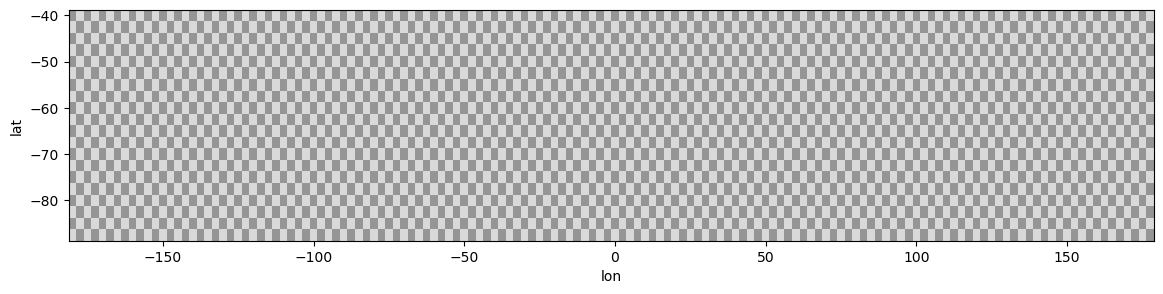

In [16]:
#(t): Quick look: the 2.5° grid as a chessboard on a flat latitude-longitude plot. Every square is one cell
grid_checker_da = (grid_lat_index_da + grid_lon_index_da) % 2
grid_checker_da.plot(cmap='Greys', vmin=-1, vmax=3, add_colorbar=False, figsize=(14, 3));

**(2) The model's grid, and what its file holds**

In [ ]:
#(t): The sample's model files: one member of each model and experiment for 2013-2014, on each model's own grid
sample_dir = SAMPLE_DIR / 'lesfmip'
sample_dir

In [18]:
#(t): EXAMPLE_MODEL's historical file, and the file of its grid's cell areas (areacello: the ocean model's)
example_path = sample_dir / f'{EXAMPLE_MODEL}_historical_siconc_r1i1p1f1_gn.nc'
example_area_path = sample_dir / f'{EXAMPLE_MODEL}_areacello_gn.nc'
example_path, example_area_path

(PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_historical_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_areacello_gn.nc'))

In [19]:
#(t): The file as it is
example_native_ds = xr.open_dataset(example_path)
example_native_ds

<xarray.Dataset> Size: 6MB
Dimensions:             (time: 24, bnds: 2, j: 88, i: 360, vertices: 4)
Coordinates:
  * time                (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16...
  * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
  * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
    latitude            (j, i) float64 253kB ...
    longitude           (j, i) float64 253kB ...
    type                |S7 7B ...
Dimensions without coordinates: bnds, vertices
Data variables:
    time_bnds           (time, bnds) object 384B ...
    vertices_latitude   (j, i, vertices) float64 1MB ...
    vertices_longitude  (j, i, vertices) float64 1MB ...
    siconc              (time, j, i) float32 3MB ...
Attributes: (53)

**What is in the file**

- `siconc` (time, j, i): the concentration at each model point, each month (%); empty over land.
- `latitude`, `longitude` (j, i): where each model point is.
- `j`, `i`: the file keeps the model points in arrays of 88 × 360 values (the sample stops at 40°S). `j` (0–87) and `i` (0–359) are a point's place in these arrays, not on the Earth. The same `j, i` in each array is the same point: `latitude[50, 2]`, `longitude[50, 2]` and `siconc[:, 50, 2]` are where one point is and how much ice it has. MIROC6 calls them `y` and `x`.
- `vertices_latitude`, `vertices_longitude` (j, i, vertices): the four corners of each model cell. Used only to draw the cells and to check their areas, below.
- `time_bnds`: the start and end of each month. Not used.
- `type`: a label, `sea_ice`. Not used.

In [20]:
#(t): One model point (j = 50, i = 2): where it is and its ice in September 2013 (62.7°S, 75.5°E, 96%).
#(t): Steps 3 and 4 follow this point
one_point = dict(j=50, i=2)
(float(example_native_ds['latitude'].isel(one_point)),
 float(example_native_ds['longitude'].isel(one_point)),
 float(example_native_ds['siconc'].sel(time='2013-09').isel(one_point).squeeze()))

(-62.65800094604492, 75.5, 96.49372100830078)

**What j and i are.** `j` and `i` are not positions on the Earth. They only say where a number sits in the file's arrays: `j` counts up the array (from 0 at the bottom) and `i` across it (from 0 on the left). Where each point is on the Earth is stored separately, in two more arrays, `latitude` and `longitude`, laid out the same way. So the numbers at the same `j, i` in `latitude`, `longitude` and `siconc` all belong to one point.

Below: a 5 × 5 block of the three arrays around the point above (j = 48–52, i = 0–4), then where those 25 points are on the Earth.

In [ ]:
#(t): Diagram: a 5 × 5 block of three of the file's arrays, j = 48-52 (up) and i = 0-4 (across), each box one number.
#(t): The red box is the same j, i in each, so the same point: 62.66°S, 75.5°E, 96.5% ice
block = dict(j=slice(48, 53), i=slice(0, 5))
block_list = [('latitude (°)', example_native_ds['latitude'].isel(block)),
              ('longitude (°E)', example_native_ds['longitude'].isel(block)),
              ('siconc, September 2013 (%)', example_native_ds['siconc'].sel(time='2013-09').squeeze('time').isel(block))]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, block_da) in zip(axes, block_list):
    for j in block_da['j'].values:
        for i in block_da['i'].values:
            ax.add_patch(plt.Rectangle((i - 0.5, j - 0.5), 1, 1, fill=False, edgecolor='0.6'))
            ax.text(i, j, f'{float(block_da.sel(j=j, i=i)):.2f}', ha='center', va='center', fontsize=9)
    ax.add_patch(plt.Rectangle((2 - 0.5, 50 - 0.5), 1, 1, fill=False, edgecolor='r', linewidth=2))
    ax.set(xlim=(-0.5, 4.5), ylim=(47.5, 52.5), xticks=range(0, 5), yticks=range(48, 53), xlabel='i', ylabel='j',
           title=name)

In [ ]:
#(t): Diagram: the same 25 points on the Earth, each labelled (j, i), in its model cell (grey, drawn from its four
#(t): corners). Here a step in i is 1° east and a step in j about 0.46° north. i = 0 is at 73.5°E only because that is
#(t): where CanESM5's arrays happen to start
block_lat_da = example_native_ds['latitude'].isel(block)
block_lon_da = example_native_ds['longitude'].isel(block)
block_corner_lat_da = example_native_ds['vertices_latitude'].isel(block)
block_corner_lon_da = example_native_ds['vertices_longitude'].isel(block)
fig, ax = plt.subplots(figsize=(8, 6))
for j in block_lat_da['j'].values:
    for i in block_lat_da['i'].values:
        ax.fill(block_corner_lon_da.sel(j=j, i=i), block_corner_lat_da.sel(j=j, i=i), facecolor='none', edgecolor='0.75')
        ax.annotate(f'({j}, {i})', (float(block_lon_da.sel(j=j, i=i)), float(block_lat_da.sel(j=j, i=i))),
                    xytext=(3, 3), textcoords='offset points', fontsize=8)
#(c): Each solid line joins the points of one j (i going 0 to 4); each dashed line those of one i (j going 48 to 52)
ax.plot(block_lon_da.transpose('i', 'j'), block_lat_da.transpose('i', 'j'), color='C0')
ax.plot(block_lon_da, block_lat_da, color='C1', linestyle='--')
ax.scatter(block_lon_da, block_lat_da, color='k', s=15, zorder=3)
ax.scatter(block_lon_da.sel(j=50, i=2), block_lat_da.sel(j=50, i=2), s=150, facecolor='none', edgecolor='r',
           linewidth=2, zorder=4)
ax.legend(handles=[plt.Line2D([], [], color='C0', label='one j: i going 0 → 4 is east'),
                   plt.Line2D([], [], color='C1', linestyle='--', label='one i: j going 48 → 52 is north')],
          loc='upper left', bbox_to_anchor=(1, 1))
ax.set(xlabel='longitude (°E)', ylabel='latitude (°)');

**Why latitude and longitude are 2-D arrays.** On the 2.5° grid one latitude per row is enough. An ocean model's rows don't have to follow latitude circles. To keep the grid's own poles off the ocean, a model moves them onto land, and its rows bend round them. Then the points along one row are at different latitudes, so every point needs its own latitude and longitude. CanESM5's grid uses the real South Pole, so south of 40°S its rows happen to be latitude circles. MPI-ESM1-2-LR moves its southern pole off the South Pole, so its rows are bent here.

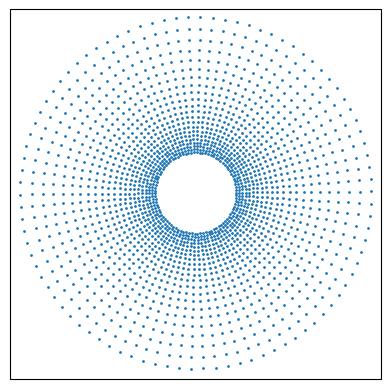

In [21]:
#(t): Quick look: every fourth row and column of the points on a map
fig, ax = plt.subplots(subplot_kw=dict(projection=ccrs.SouthPolarStereo()))
ax.scatter(example_native_ds['longitude'][::4, ::4], example_native_ds['latitude'][::4, ::4], s=1, transform=ccrs.PlateCarree())
ax.set_extent([-180, 180, -90, -40], ccrs.PlateCarree());

In [ ]:
#(t): MPI-ESM1-2-LR's file, to compare its grid with CanESM5's. The sample is cut from its whole arrays and keeps their
#(t): numbers: j runs from 154 (about 30°S) to 219 (near the coast), so MPI-ESM1-2-LR counts j from the north
mpi_native_ds = xr.open_dataset(sample_dir / 'MPI-ESM1-2-LR_historical_siconc_r1i1p1f1_gn.nc')
mpi_native_ds['j'].values

In [ ]:
#(t): Quick look: the latitude along one line of equal j, all the way round. CanESM5's j = 50 stays at 62.7°S;
#(t): MPI-ESM1-2-LR's j = 194 swings between 74°S and 62°S
example_native_ds['latitude'].sel(j=50).plot.line(x='i', label='CanESM5, j = 50')
mpi_native_ds['latitude'].sel(j=194).plot.line(x='i', label='MPI-ESM1-2-LR, j = 194')
plt.legend();

In [ ]:
#(t): Diagram: each whole grid as its lines of equal j (blue, every 5th) and of equal i (orange, every 20th). CanESM5's
#(t): lines of equal j are latitude circles round the South Pole, and its lines of equal i meridians. MPI-ESM1-2-LR's are
#(t): circles round its grid's own pole, moved off the South Pole onto Antarctica (red: j = 194, the line above)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), subplot_kw=dict(projection=ccrs.SouthPolarStereo()))
for ax, (name, native_ds) in zip(axes, [('CanESM5', example_native_ds), ('MPI-ESM1-2-LR', mpi_native_ds)]):
    lat_da, lon_da = native_ds['latitude'], native_ds['longitude']
    #(c): Geodetic: each line goes the short way between neighbouring points, also across 0°E (359.5° to 0.5°)
    ax.plot(lon_da.isel(j=slice(None, None, 5)).transpose('i', 'j'), lat_da.isel(j=slice(None, None, 5)).transpose('i', 'j'),
            color='C0', linewidth=0.8, transform=ccrs.Geodetic())
    ax.plot(lon_da.isel(i=slice(None, None, 20)), lat_da.isel(i=slice(None, None, 20)), color='C1', linewidth=0.8,
            transform=ccrs.Geodetic())
    ax.coastlines(color='0.5')
    ax.set_extent([-180, 180, -90, -40], ccrs.PlateCarree())
    ax.set_title(name)
axes[1].plot(mpi_native_ds['longitude'].sel(j=194), mpi_native_ds['latitude'].sel(j=194), color='r', linewidth=2,
             transform=ccrs.Geodetic());

In [ ]:
#(t): Check: MPI-ESM1-2-LR's arrays wrap round with two extra columns. i = 254 and 255 repeat i = 0 and 1: the same
#(t): latitudes, longitudes and ice (largest differences: 0). onto_grid would count those points twice, so
#(t): file_onto_grid (section 2) drops the two columns
(float(np.nanmax(abs(mpi_native_ds['latitude'].isel(i=[254, 255]).values - mpi_native_ds['latitude'].isel(i=[0, 1]).values))),
 float(np.nanmax(abs(mpi_native_ds['longitude'].isel(i=[254, 255]).values - mpi_native_ds['longitude'].isel(i=[0, 1]).values))),
 float(np.nanmax(abs(mpi_native_ds['siconc'].isel(i=[254, 255]).values - mpi_native_ds['siconc'].isel(i=[0, 1]).values))))

**Drawing a model's field.** `.plot()` on an array on (j, i) draws it by place in the arrays (`i` across, `j` up). That's a picture of the arrays, not a map. For a map, xarray needs each point's position: `x='longitude', y='latitude'`.

In [24]:
#(t): One month, September 2013, at every model point
example_native_da = example_native_ds['siconc'].sel(time='2013-09').squeeze('time', drop=True)

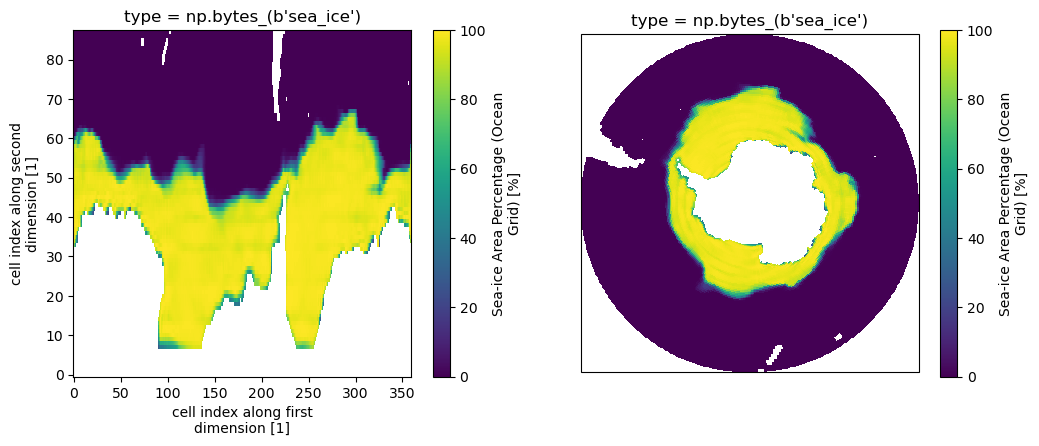

In [25]:
#(t): Quick look: drawn by place in the arrays (left: Antarctica is the white at the bottom, the lowest j), and on a
#(t): map, each point at its own latitude and longitude (right)
fig = plt.figure(figsize=(12, 4.5))
ax_arrays = fig.add_subplot(1, 2, 1)
example_native_da.plot(ax=ax_arrays, vmin=0, vmax=100)
ax_map = fig.add_subplot(1, 2, 2, projection=ccrs.SouthPolarStereo())
example_native_da.plot(ax=ax_map, x='longitude', y='latitude', transform=ccrs.PlateCarree(), vmin=0, vmax=100);

In [26]:
#(t): The file of the grid's cell areas: areacello, the ocean model's, in m², on the same (j, i)
example_area_ds = xr.open_dataset(example_area_path)
example_area_ds

<xarray.Dataset> Size: 3MB
Dimensions:             (j: 88, i: 360, vertices: 4)
Coordinates:
  * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
  * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
    latitude            (j, i) float64 253kB ...
    longitude           (j, i) float64 253kB ...
Dimensions without coordinates: vertices
Data variables:
    vertices_latitude   (j, i, vertices) float64 1MB ...
    vertices_longitude  (j, i, vertices) float64 1MB ...
    areacello           (j, i) float32 127kB ...
Attributes: (52)

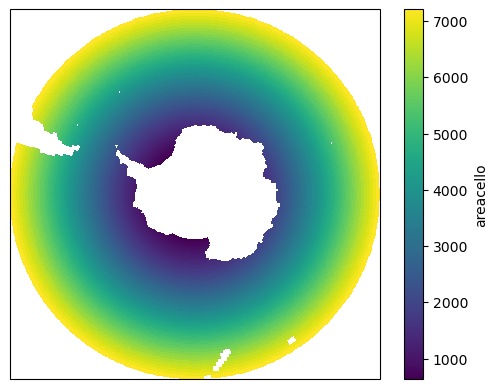

In [27]:
#(t): Each model cell's area, in km² (smaller towards the pole)
example_point_area_da = example_area_ds['areacello'] / 1e6
example_point_area_da.plot(x='longitude', y='latitude', **POLAR);

**The two grids together.** Zoomed in on a small patch (56–69°S, 0–14°E): the model's points (dots) and the 2.5° grid's cells (blue lines). Here CanESM5's points are 1° apart in longitude and about 0.5° apart in latitude, so each 2.5° cell holds about a dozen. Each 2.5° cell will get the mean of the points inside it, but first each point has to be matched to its cell.

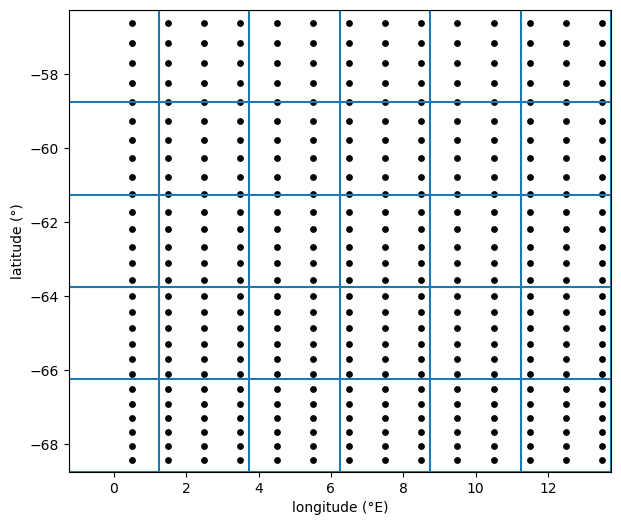

In [28]:
#(t): Quick look: a small patch of the model's points (dots) and the 2.5° grid's cell edges (blue lines)
patch_da = ((example_native_ds['latitude'] > -68.75) & (example_native_ds['latitude'] < -56.25)
            & (example_native_ds['longitude'] < 13.75))
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(example_native_ds['longitude'].where(patch_da), example_native_ds['latitude'].where(patch_da), s=15, color='k')
ax.hlines(np.arange(-68.75, -56, 2.5), -1.25, 13.75, color='C0')
ax.vlines(np.arange(-1.25, 14, 2.5), -68.75, -56.25, color='C0')
ax.set(xlabel='longitude (°E)', ylabel='latitude (°)', xlim=(-1.25, 13.75), ylim=(-68.75, -56.25));

**(3) Which 2.5° cell each model point is in**

Each model point gets the lat index of the 2.5° cell it's in, and from that the cell's centre. The 2.5° rows start at 88.75°S (the southern edge of row 0) and are 2.5° tall, so for the point above at 62.66°S:

1. **How far north of 88.75°S it is, counted in 2.5° steps:** (−62.66 + 88.75) / 2.5 = **10.44**. This is a position, like a reading on a ruler, so it needn't be whole: the point is past 10 whole rows and 44% of the way across the next.
2. **The lat index:** round down, **10**.
3. **That row's centre:** −87.5 + 2.5 × 10 = **62.5°S**.

```
lat index:     9           10           11
       |-----------|-----------|-----------|
   66.25°S     63.75°S     61.25°S     58.75°S
                     ^
           the point at 62.66°S: 10.44 steps from 88.75°S → in lat index 10
```

Longitude works the same way, from the western edge of column 0 (181.25°W): 75.5°E is (75.5 + 181.25) / 2.5 = 102.7 steps, so lon index 102, centred on −180 + 2.5 × 102 = **75°E**. The `% 360` puts the models' 0–360° longitudes onto the grid's −180–180°, so 350°E and 10°W land in the same column.

In [29]:
#(t): 1. How far north of 88.75°S each model point is, in 2.5° steps (the point above: 10.44)
example_lat_steps_da = (example_native_ds['latitude'] + 88.75) / 2.5
float(example_lat_steps_da.isel(one_point))

10.436799621582031

In [30]:
#(t): 2. The lat index of the 2.5° cell each model point is in: rounded down (10.44 -> 10)
example_lat_index_da = np.floor(example_lat_steps_da)
float(example_lat_index_da.isel(one_point))

10.0

In [31]:
#(t): 3. That cell's centre latitude (10 -> 62.5°S)
example_cell_lat_da = -87.5 + 2.5 * example_lat_index_da
float(example_cell_lat_da.isel(one_point))

-62.5

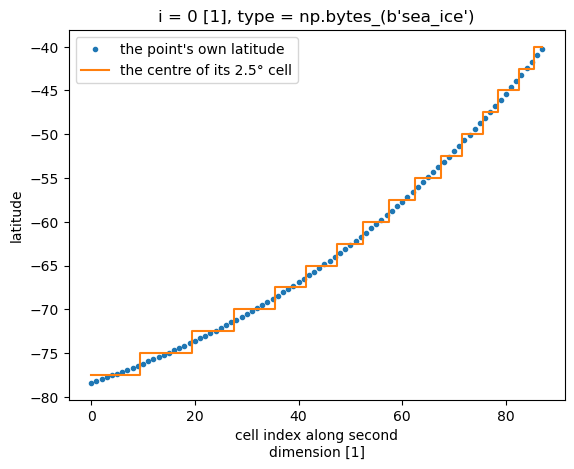

In [32]:
#(t): Quick look: one column of model points (i = 0), south to north. The dots are the points' own latitudes, the line
#(t): their 2.5° cells' centres. The points along one flat step share a cell
example_native_ds['latitude'].isel(i=0).plot.line(x='j', marker='.', ls='none', label="the point's own latitude")
example_cell_lat_da.isel(i=0).plot.line(x='j', drawstyle='steps-mid', label="the centre of its 2.5° cell")
plt.legend();

In [33]:
#(t): The same for longitude, in one go: the centre longitude of each model point's 2.5° cell (75.5°E -> 75°E)
example_cell_lon_da = -180 + 2.5 * np.floor(((example_native_ds['longitude'] + 181.25) % 360) / 2.5)
float(example_cell_lon_da.isel(one_point))

75.0

In [34]:
#(t): Check: no point is more than half a cell (1.25°) from its cell's centre, in latitude or in longitude (taken
#(t): round the globe)
(float(abs(example_cell_lat_da - example_native_ds['latitude']).max()),
 float(abs((example_cell_lon_da - example_native_ds['longitude'] + 180) % 360 - 180).max()))

(1.2489547729492188, 1.0)

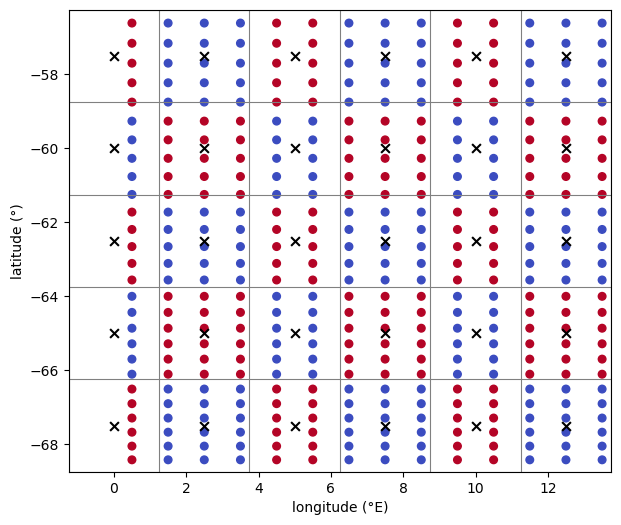

In [35]:
#(t): Quick look: the patch again, each point coloured by its 2.5° cell (alternating like a chessboard), with the
#(t): cells' edges and centres (x). The points of one colour inside one square are averaged together in step 4
checker_da = (example_cell_lat_da / 2.5 + example_cell_lon_da / 2.5) % 2
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(example_native_ds['longitude'].where(patch_da), example_native_ds['latitude'].where(patch_da),
           c=checker_da.where(patch_da), cmap='coolwarm', s=30)
ax.hlines(np.arange(-68.75, -56, 2.5), -1.25, 13.75, color='0.5', lw=0.8)
ax.vlines(np.arange(-1.25, 14, 2.5), -68.75, -56.25, color='0.5', lw=0.8)
ax.scatter(*np.meshgrid(np.arange(0, 13, 2.5), np.arange(-67.5, -57, 2.5)), marker='x', color='k', s=40)
ax.set(xlabel='longitude (°E)', ylabel='latitude (°)', xlim=(-1.25, 13.75), ylim=(-68.75, -56.25));

**(4) The mean in each 2.5° cell**

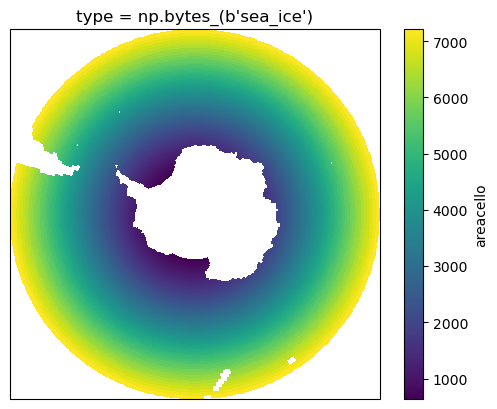

In [36]:
#(t): Each point's area where it is ocean, i.e. where it has a concentration (km²; empty over land)
example_ocean_point_area_da = example_point_area_da.where(example_native_da.notnull())
example_ocean_point_area_da.plot(x='longitude', y='latitude', **POLAR);

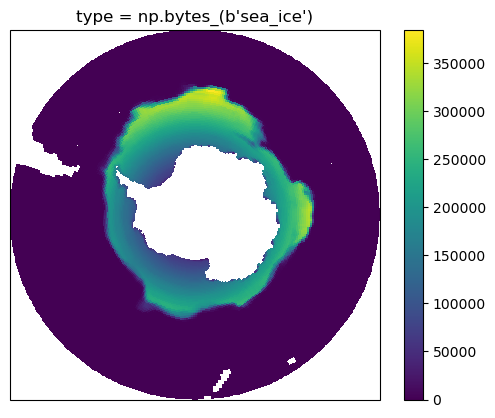

In [37]:
#(t): Each point's area times its concentration (km² × %)
example_weighted_siconc_da = example_point_area_da * example_native_da
example_weighted_siconc_da.plot(x='longitude', y='latitude', **POLAR);

In [38]:
#(t): The two side by side, each point labelled with the centre of its cell
example_points_ds = xr.Dataset({'weighted_siconc': example_weighted_siconc_da, 'ocean_area': example_ocean_point_area_da},
                               coords={'cell_lat': example_cell_lat_da, 'cell_lon': example_cell_lon_da})
example_points_ds

<xarray.Dataset> Size: 1MB
Dimensions:          (j: 88, i: 360)
Coordinates:
  * j                (j) int32 352B 0 1 2 3 4 5 6 7 ... 80 81 82 83 84 85 86 87
  * i                (i) int32 1kB 0 1 2 3 4 5 6 ... 353 354 355 356 357 358 359
    latitude         (j, i) float64 253kB -78.39 -78.39 -78.39 ... -40.22 -40.22
    longitude        (j, i) float64 253kB 73.5 74.5 75.5 76.5 ... 70.5 71.5 72.5
    type             |S7 7B b'sea_ice'
    cell_lat         (j, i) float64 253kB -77.5 -77.5 -77.5 ... -40.0 -40.0
    cell_lon         (j, i) float64 253kB 72.5 75.0 75.0 77.5 ... 70.0 72.5 72.5
Data variables:
    weighted_siconc  (j, i) float32 127kB nan nan nan nan ... 0.0 0.0 0.0 0.0
    ocean_area       (j, i) float32 127kB nan nan nan ... 7.209e+03 7.209e+03

In [39]:
#(t): Summed over the points of each 2.5° cell: the points with the same cell centre are grouped together
example_sums_ds = example_points_ds.groupby(['cell_lat', 'cell_lon']).sum()
example_sums_ds

<xarray.Dataset> Size: 20kB
Dimensions:          (cell_lat: 16, cell_lon: 144)
Coordinates:
    type             |S7 7B b'sea_ice'
  * cell_lat         (cell_lat) float64 128B -77.5 -75.0 -72.5 ... -42.5 -40.0
  * cell_lon         (cell_lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
Data variables:
    weighted_siconc  (cell_lat, cell_lon) float32 9kB 2.906e+05 ... 0.0
    ocean_area       (cell_lat, cell_lon) float32 9kB 3.946e+03 ... 3.556e+04

In [40]:
#(t): The cells named lat and lon, as in the temperature's files
example_named_sums_ds = example_sums_ds.rename(cell_lat='lat', cell_lon='lon')

In [41]:
#(t): On the whole 2.5° grid. A cell with no point has nothing in its sums: 0 (the groupby and reindex leave it empty)
#(c): Points outside the grid drop out here: north of 38.75°S, or with 1e30 for a position (NorESM2-LM over some land)
example_grid_sums_ds = example_named_sums_ds.reindex(lat=GRID_LAT, lon=GRID_LON).fillna(0)
example_grid_sums_ds

<xarray.Dataset> Size: 24kB
Dimensions:          (lat: 20, lon: 144)
Coordinates:
  * lat              (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * lon              (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
    type             |S7 7B b'sea_ice'
Data variables:
    weighted_siconc  (lat, lon) float32 12kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    ocean_area       (lat, lon) float32 12kB 0.0 0.0 0.0 ... 2.13e+04 3.556e+04

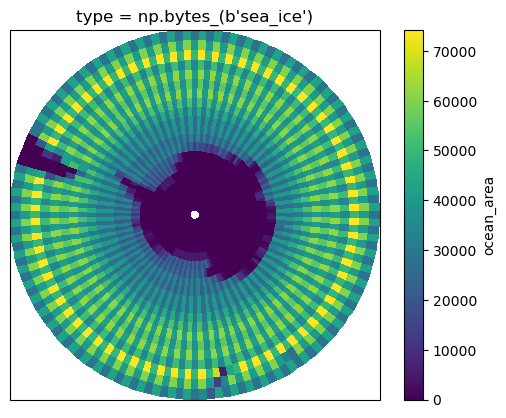

In [42]:
#(t): How much of each 2.5° cell is ocean (km²): the summed areas of its points with a concentration
example_ocean_area_da = example_grid_sums_ds['ocean_area']
example_ocean_area_da.plot(**POLAR);

In [ ]:
#(t): Check: no ocean is lost or gained. The 2.5° cells' ocean adds up to the model points' (km²)
float(example_ocean_area_da.sum()), float(example_ocean_point_area_da.sum())

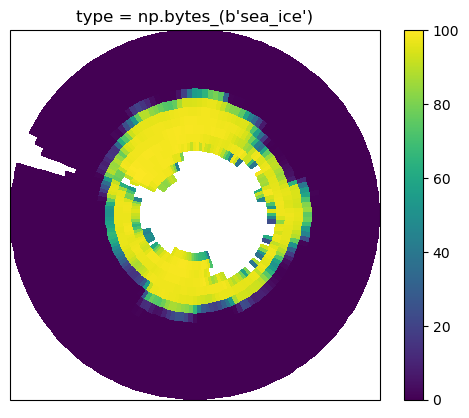

In [43]:
#(t): The mean concentration: the summed area × concentration over the ocean area; empty where a cell has no ocean
example_grid_da = example_grid_sums_ds['weighted_siconc'] / example_ocean_area_da.where(example_ocean_area_da > 0)
example_grid_da.plot(vmin=0, vmax=100, **POLAR);

In [ ]:
#(t): Check: no ice is lost or gained either. Area × concentration summed over the 2.5° cells, and over the model's
#(t): points (km² × %)
float((example_grid_da * example_ocean_area_da).sum()), float(example_weighted_siconc_da.sum())

**How much of each cell is ocean**

That needs each 2.5° cell's whole area. A cell spans Δλ of longitude, from latitude φ_south to φ_north, and its area is

$$A = R^2\,\Delta\lambda\,(\sin\varphi_\text{north} - \sin\varphi_\text{south})$$

with R the Earth's radius and Δλ in radians. Where it comes from, in two steps, each with a diagram below:

1. **A cell is nearly a rectangle.** Its height is R Δφ, the same everywhere: 2.5° of latitude is 278 km. Its width is R cos φ Δλ, because the circle of latitude φ has radius R cos φ: 2.5° of longitude is 278 km at the equator, 128 km at 62.5°S and 12 km at 87.5°S. So A ≈ width × height = R² Δλ cos φ Δφ, and the cells get narrower towards the pole.
2. **The exact area.** Seen from the side, the band of the Earth between φ_south and φ_north covers a height h = R (sin φ_north − sin φ_south) along the Earth's axis. The band has the same area as a cylinder wrapped round the Earth over that same height, 2πR × h (Archimedes): the band is shorter round than the cylinder (radius R cos φ instead of R) but longer from edge to edge, because it slopes, and the two cancel. A cell is the share Δλ / 2π of its band, which gives the formula.

The same formula gives ERA5's 0.25° cells in section 2. It works only for cells bounded by latitude circles and meridians: the models' tilted cells (MPI-ESM1-2-LR's) are not, which is why their areas come from their areacello files.

In [ ]:
#(t): The grid's cell centres, as DataArrays for the sums below
grid_lat_da = xr.DataArray(GRID_LAT, dims='lat', coords={'lat': GRID_LAT})
grid_lon_da = xr.DataArray(GRID_LON, dims='lon', coords={'lon': GRID_LON})

In [ ]:
#(t): Diagram: a 30° slice of the 2.5° grid (the chessboard of (1), 0-30°E) on a map round the pole. Every cell is 2.5°
#(t): by 2.5°, but the cells get narrower towards the pole: the widths written in are R cos φ Δλ, from step 1 below
fig, ax = plt.subplots(figsize=(6, 7), subplot_kw=dict(projection=ccrs.SouthPolarStereo()))
grid_checker_da.sel(lon=slice(0, 27.5)).plot(ax=ax, cmap='Greys', vmin=-1, vmax=3, add_colorbar=False,
                                             transform=ccrs.PlateCarree())
for lat in [-40, -62.5, -85]:
    width = EARTH_RADIUS * np.cos(np.deg2rad(lat)) * np.deg2rad(2.5)
    ax.text(31, lat, f'{lat}°: {width:.0f} km wide', transform=ccrs.PlateCarree(), va='center', fontsize=9)
ax.set_extent([-5, 60, -90, -36], ccrs.PlateCarree())
ax.coastlines(color='0.5');

In [ ]:
#(t): Step 1: a 2.5° cell's height, R Δφ, the same at every latitude, and its width, R cos φ Δλ (km)
cell_height_da = EARTH_RADIUS * np.deg2rad(2.5) * xr.ones_like(grid_lat_da)
cell_width_da = EARTH_RADIUS * np.cos(np.deg2rad(grid_lat_da)) * np.deg2rad(2.5)

In [ ]:
#(t): Diagram: the height and width of a 2.5° cell at each latitude of the grid (km). Near the pole the cells are tall
#(t): and thin
fig, ax = plt.subplots(figsize=(7, 4))
cell_height_da.plot(ax=ax, marker='.', label='height, R Δφ')
cell_width_da.plot(ax=ax, marker='.', label='width, R cos φ Δλ')
ax.set(ylabel='km', title='')
ax.legend();

In [ ]:
#(t): Diagram, step 2: the Earth seen from the side (radius 1), with a band between 70°S and 50°S (blue; much wider than
#(t): a cell, to be seen). Its height along the axis is h = R (sin φ_north − sin φ_south). The cylinder round the Earth
#(t): over the same height (orange) has the same area, 2πR h
band_south, band_north = np.deg2rad(-70), np.deg2rad(-50)
circle_arr = np.linspace(0, 2 * np.pi, 400)
band_arr = np.linspace(band_south, band_north, 50)
fig, ax = plt.subplots(figsize=(7, 7))
#(c): The Earth, its axis, and the cylinder touching it at the equator (dotted)
ax.plot(np.cos(circle_arr), np.sin(circle_arr), color='k')
ax.plot([0, 0], [-1.15, 1.15], color='0.4', linewidth=0.8)
ax.plot([-1, -1], [-1.15, 1.15], color='C1', linestyle=':')
ax.plot([1, 1], [-1.15, 1.15], color='C1', linestyle=':')
#(c): The band on the Earth (both sides), and the piece of the cylinder over the same height
ax.plot(np.cos(band_arr), np.sin(band_arr), color='C0', linewidth=6)
ax.plot(-np.cos(band_arr), np.sin(band_arr), color='C0', linewidth=6)
ax.plot([1, 1], [np.sin(band_south), np.sin(band_north)], color='C1', linewidth=6)
ax.plot([-1, -1], [np.sin(band_south), np.sin(band_north)], color='C1', linewidth=6)
#(c): The band's edges across the Earth, and the radii to them at angles φ_north and φ_south from the equator
ax.hlines([np.sin(band_south), np.sin(band_north)], -1, 1, color='0.6', linestyle='--')
ax.plot([0, np.cos(band_north)], [0, np.sin(band_north)], color='0.3')
ax.plot([0, np.cos(band_south)], [0, np.sin(band_south)], color='0.3')
ax.plot([0, 1], [0, 0], color='0.3')
ax.text(0.45, 0.03, 'R')
ax.text(0.5 * np.cos(band_north) + 0.04, 0.5 * np.sin(band_north), 'φ_north = 50°S', ha='left', fontsize=9)
ax.text(0.5 * np.cos(band_south) - 0.04, 0.5 * np.sin(band_south), 'φ_south = 70°S', ha='right', fontsize=9)
#(c): The band's radius round the axis, R cos φ: smaller than the cylinder's, R
ax.text(-0.5 * np.cos(band_north), np.sin(band_north) + 0.03, 'R cos φ_north', ha='center', fontsize=9)
#(c): The height h along the axis
ax.annotate('', xy=(1.12, np.sin(band_north)), xytext=(1.12, np.sin(band_south)), arrowprops=dict(arrowstyle='<->'))
ax.text(1.16, (np.sin(band_north) + np.sin(band_south)) / 2, 'h = R (sin φ_north − sin φ_south)', va='center')
ax.text(-1.05, 1.25, 'The band (blue) is shorter round than the cylinder (orange), but slopes, so it is longer from\n'
                     'edge to edge. The two cancel: both have the area 2πR h', fontsize=10)
ax.set(xlim=(-1.1, 1.2), aspect='equal')
ax.axis('off');

In [ ]:
#(t): Worked example: the 2.5° cell centred on 62.5°S. Its edges, half a cell either side (degrees)
example_cell_north, example_cell_south = -62.5 + 1.25, -62.5 - 1.25
example_cell_north, example_cell_south

In [ ]:
#(t): The height of its band along the axis, R (sin φ_north − sin φ_south) (km)
example_band_height = EARTH_RADIUS * (np.sin(np.deg2rad(example_cell_north)) - np.sin(np.deg2rad(example_cell_south)))
example_band_height

In [ ]:
#(t): The band's area, 2πR h, and the cell's share of it, Δλ / 2π with Δλ = 2.5° in radians: the cell's area (km²)
example_band_area = 2 * np.pi * EARTH_RADIUS * example_band_height
example_cell_area = example_band_area * np.deg2rad(2.5) / (2 * np.pi)
example_band_area, example_cell_area

In [ ]:
#(t): ... and step 1's width × height for the same cell (km²): almost the same
float(cell_width_da.sel(lat=-62.5) * cell_height_da.sel(lat=-62.5))

In [ ]:
#(t): The formula as a function, for every cell of a regular latitude-longitude grid
def cell_area(lat_da, lon_da, spacing):
    """Each cell's area, R² Δλ (sin φ_north − sin φ_south), its edges half a spacing either side of its centre.

    Args:
        lat_da, lon_da (xr.DataArray): the cells' centres (degrees), 1-D
        spacing (float): the grid's spacing (degrees): 2.5 for the temperature's grid, 0.25 for ERA5's

    Returns:
        xr.DataArray: each cell's area (km²) on (lat, lon). E.g. the 2.5° cell centred on 62.5°S: 35,680 km²
    """
    #(c): The northern and southern edges (none beyond a pole). In float64: ERA5's latitudes are float32, too coarse
    #(c): for the difference of two sines 0.25° apart
    north_da = np.deg2rad(np.minimum(lat_da.astype('float64') + spacing / 2, 90))
    south_da = np.deg2rad(np.maximum(lat_da.astype('float64') - spacing / 2, -90))
    #(c): The same at every longitude
    return EARTH_RADIUS ** 2 * np.deg2rad(spacing) * (np.sin(north_da) - np.sin(south_da)) * xr.ones_like(lon_da)

In [ ]:
#(t): Each 2.5° cell's whole area (km²), larger towards the equator: from the formula (dots), and step 1's width × height
#(t): (line), the same to within 0.01%
grid_cell_area_da = cell_area(grid_lat_da, grid_lon_da, 2.5)
grid_cell_area_da.isel(lon=0).plot(marker='o', linestyle='none', label='R² Δλ (sin φ_north − sin φ_south)')
(cell_width_da * cell_height_da).plot(label='width × height')
plt.ylabel('km²')
plt.legend();

In [ ]:
#(t): Check: the cell centred on 62.5°S (the worked example: 35,680 km²), and all the cells together against the band they cover, 88.75°S
#(t): to 38.75°S: 2πR² (sin(−38.75°) − sin(−88.75°)) (km²)
(float(grid_cell_area_da.sel(lat=-62.5, lon=0)),
 float(grid_cell_area_da.sum()), 2 * np.pi * EARTH_RADIUS ** 2 * (np.sin(np.deg2rad(-38.75)) - np.sin(np.deg2rad(-88.75))))

In [ ]:
#(t): Check: the formula also gives a model's own cell areas where its cells are latitude-longitude boxes, as
#(t): CanESM5's are south of 40°S. Each cell's northern and southern edges, from its four corners (radians)
example_corner_north_da = np.deg2rad(example_area_ds['vertices_latitude'].max('vertices'))
example_corner_south_da = np.deg2rad(example_area_ds['vertices_latitude'].min('vertices'))

In [ ]:
#(t): ... and its width in longitude (degrees). A cell across 0°E has corners at 359° and 0°: 359 apart in the numbers,
#(t): 1° on the Earth
example_corner_width_da = (example_area_ds['vertices_longitude'].max('vertices')
                           - example_area_ds['vertices_longitude'].min('vertices'))
example_corner_width_da = xr.where(example_corner_width_da > 180, 360 - example_corner_width_da, example_corner_width_da)

In [ ]:
#(t): The formula's area of each of CanESM5's cells (km²)
example_formula_area_da = (EARTH_RADIUS ** 2 * np.deg2rad(example_corner_width_da)
                           * (np.sin(example_corner_north_da) - np.sin(example_corner_south_da)))

In [ ]:
#(t): Check: against the areas in its areacello file: the cell of the point above (km²), and the largest difference
#(t): anywhere (%)
(float(example_formula_area_da.isel(one_point)), float(example_point_area_da.isel(one_point)),
 float(100 * abs(example_formula_area_da / example_point_area_da - 1).max()))

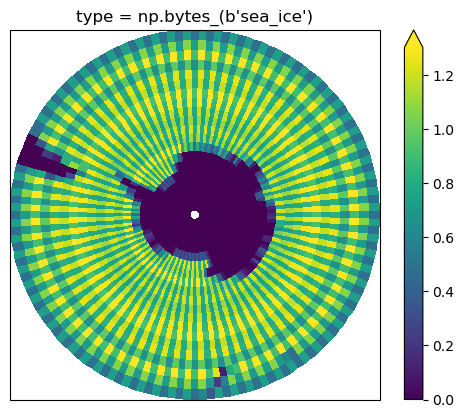

In [46]:
#(t): The ocean's share of each cell: 1 at sea, less on the coast, 0 on the continent
#(c): A share a little over 1 is a cell that got one more row of points than its neighbour
example_ocean_share_da = example_ocean_area_da / grid_cell_area_da
example_ocean_share_da.plot(vmin=0, vmax=1.3, **POLAR);

In [47]:
#(t): Check: the extent (million km²) on the model's own grid, and on the 2.5° grid counting each cell's ocean
example_own_grid_extent = float((example_point_area_da * (example_native_da >= THRESHOLD)).sum()) / 1e6
example_on_grid_extent = float(example_ocean_area_da.where(example_grid_da >= THRESHOLD, 0).sum()) / 1e6
example_own_grid_extent, example_on_grid_extent

(20.003472, 20.950728)

In [ ]:
#(t): The example's field on both grids, for plot_02's figure of the method
regrid_example_ds = xr.Dataset({'native': example_native_da, 'native_lat': example_native_ds['latitude'], 'native_lon': example_native_ds['longitude'],
                                'on_grid': example_grid_da})
#(c): Without the file's label, type (bytes, which zarr has no standard way to store)
regrid_example_ds = regrid_example_ds.drop_vars('type')

In [ ]:
#(t): Saved. It is the sample whichever data is used, so outside the run folders (plot_02 opens it from here)
regrid_example_path = SCRATCH_DIR / 'results' / 'siconc' / 'regrid_example.zarr'
regrid_example_ds.to_zarr(regrid_example_path, mode='w')
regrid_example_path

**The same steps as one function**

`onto_grid` does the steps above for one member's concentration on (time, its own grid). Every file in section 2 goes through it.

In [ ]:
#(t): The steps above as one function
def onto_grid(siconc_da, point_area_da, lat_da, lon_da):
    """One record's concentration on the 2.5° grid: in each cell, the area-weighted mean of the points inside it.

    Args:
        siconc_da (xr.DataArray): concentration (%) on (time, its own grid), empty over land
        point_area_da (xr.DataArray): each point's cell area (km²), on its own grid
        lat_da, lon_da (xr.DataArray): each point's latitude and longitude (2-D on an ocean grid, 1-D on a regular one)

    Returns:
        xr.Dataset: siconc (%) on (time, lat, lon), empty where a cell has no ocean; ocean_area (km²) on (lat, lon)
    """
    #(c): The centre of the 2.5° cell each point falls in (step 3)
    cell_lat_da = -87.5 + 2.5 * np.floor((lat_da + 88.75) / 2.5)
    cell_lon_da = -180 + 2.5 * np.floor(((lon_da + 181.25) % 360) / 2.5)
    #(c): Each point's area times its concentration, and its area where it is ocean, labelled with its cell
    points_ds = xr.Dataset({'weighted_siconc': point_area_da * siconc_da,
                            'ocean_area': point_area_da.where(siconc_da.notnull())},
                           coords={'cell_lat': cell_lat_da, 'cell_lon': cell_lon_da})
    #(c): Summed over each cell's points, on the whole grid; 0 in a cell with no point
    sums_ds = points_ds.groupby(['cell_lat', 'cell_lon']).sum()
    named_sums_ds = sums_ds.rename(cell_lat='lat', cell_lon='lon')
    grid_sums_ds = named_sums_ds.reindex(lat=GRID_LAT, lon=GRID_LON).fillna(0)
    #(c): The mean; the ocean is the same every month (land has no value in any), so the first month's is kept
    siconc_grid_da = grid_sums_ds['weighted_siconc'] / grid_sums_ds['ocean_area'].where(grid_sums_ds['ocean_area'] > 0)
    ocean_area_da = grid_sums_ds['ocean_area'].isel(time=0, drop=True)
    #(c): Only time, lat and lon kept as coordinates (not the file's label, type)
    return xr.Dataset({'siconc': siconc_grid_da, 'ocean_area': ocean_area_da}).reset_coords(drop=True)

In [52]:
#(t): Check: the function gives the same September 2013 as the steps above (largest difference, %)
example_function_ds = onto_grid(example_native_ds['siconc'], example_point_area_da, example_native_ds['latitude'], example_native_ds['longitude'])
float(abs(example_function_ds['siconc'].sel(time='2013-09').squeeze('time', drop=True) - example_grid_da).max())

0.0

In [ ]:
#(t): Check: each point is ocean in every month or in none (the number of points that are ocean in only some months:
#(t): 0), so the first month's ocean, which onto_grid keeps, is every month's
int((example_native_ds['siconc'].notnull().any('time') != example_native_ds['siconc'].notnull().all('time')).sum())

## 2. Opening and Processing Data

Run either **Sample data** (the files in this repository; nothing is saved), or the full data: **Daily values to monthly means** and **LESFMIP** put ERA5 and the CEDA files on the 2.5° grid and save them, and **Opening Data** opens what they saved. Either way ends with `ice_monthly_tree` (/<model>/<experiment>: `siconc` in % on member × time × lat × lon, and `ocean_area` in km² on lat × lon) and `era5_ice_ds` (ERA5's `siconc` and `ocean_area`).

Every model's file goes through section 1's `onto_grid`. GISS-E2-1-G is the one different model: its files are `siconca`, the concentration on its atmosphere grid. That grid is regular, so its positions are 1-D `lat` and `lon`; and `siconca` is 0 over land rather than empty, so its land cannot be told from open water, and it takes ERA5's ocean instead.

In [ ]:
#(t): One member's file(s), opened, onto the 2.5° grid as one member of its model
#(c): skip_empty: nodes with no data (the root, each model's node) are passed through unchanged
@skip_empty
def file_onto_grid(native_ds, area_ds, era5_ocean_area_da):
    """onto_grid for one member, with its grid's cell areas; GISS-E2-1-G's siconca takes ERA5's ocean, and
    MPI-ESM1-2-LR's siconc loses its two repeated columns.

    Args:
        native_ds (xr.Dataset): siconc (or siconca) on (time, its own grid), with its points' positions
        area_ds (xr.Dataset): its grid's cell areas (m²): areacello for siconc, areacella for siconca
        era5_ocean_area_da (xr.DataArray): ERA5's ocean in each 2.5° cell (km²)

    Returns:
        xr.Dataset: siconc (%) on (member, time, lat, lon), the member named by the file's variant_label, and
        ocean_area (km²) on (lat, lon)
    """
    #(c): siconc, or GISS-E2-1-G's siconca
    variable = 'siconca' if 'siconca' in native_ds else 'siconc'
    #(c): MPI-ESM1-2-LR's siconc arrays wrap round with two extra columns, i = 254 and 255, which repeat i = 0 and 1
    #(c): (section 1): dropped, or onto_grid would count their points twice
    if native_ds.attrs['source_id'] == 'MPI-ESM1-2-LR' and variable == 'siconc':
        native_ds = native_ds.drop_sel(i=[254, 255])
        area_ds = area_ds.drop_sel(i=[254, 255])
    lat_name, lon_name = POSITION_NAMES[variable]
    point_area_da = area_ds[AREA_VARIABLES[variable]] / 1e6
    grid_ds = onto_grid(native_ds[variable], point_area_da, native_ds[lat_name], native_ds[lon_name])
    siconc_da = grid_ds['siconc'].expand_dims(member=[native_ds.attrs['variant_label']])
    if variable == 'siconc':
        return xr.Dataset({'siconc': siconc_da, 'ocean_area': grid_ds['ocean_area']})
    #(c): siconca is 0 over land, so its own ocean is every cell: ERA5's ocean instead, and the cells with none made
    #(c): empty, as an ocean model leaves them
    return xr.Dataset({'siconc': siconc_da.where(era5_ocean_area_da > 0), 'ocean_area': era5_ocean_area_da})

### ERA5

#### Sample data

One member of each model and experiment for 2013–2014, and ERA5 at 00 UTC on the 15th of each month (`scripts/sea_ice_sample.py`).

In [ ]:
#(t): ERA5's sea-ice cover, on its regular 0.25° grid (1-D latitude and longitude), as a fraction (0-1)
era5_sample_path = SAMPLE_DIR / 'era5_ci.nc'
era5_native_ds = xr.open_dataset(era5_sample_path)
era5_native_ds

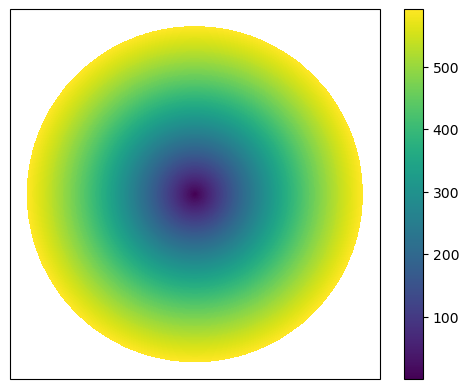

In [64]:
#(t): Each ERA5 point's area (km²): a 0.25° cell
era5_point_area_da = cell_area(era5_native_ds['latitude'], era5_native_ds['longitude'], 0.25)
era5_point_area_da.plot(**POLAR);

In [65]:
#(t): ERA5 on the 2.5° grid (section 1's steps), and each cell's ocean (ERA5 leaves land empty)
era5_grid_ds = onto_grid(era5_native_ds['siconc'], era5_point_area_da, era5_native_ds['latitude'],
                         era5_native_ds['longitude'])

<xarray.Dataset> Size: 578kB
Dimensions:     (time: 24, lat: 20, lon: 144)
Coordinates:
  * time        (time) datetime64[ns] 192B 2013-01-15 2013-02-15 ... 2014-12-15
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    siconc      (time, lat, lon) float64 553kB nan nan nan nan ... 0.0 0.0 0.0
    ocean_area  (lat, lon) float64 23kB 0.0 0.0 0.0 ... 1.879e+04 3.106e+04

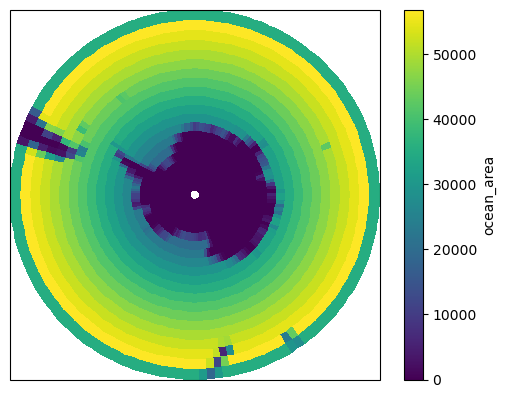

In [66]:
#(t): ERA5's ocean in each cell (km²)
era5_ocean_area_da = era5_grid_ds['ocean_area']
era5_ocean_area_da.plot(**POLAR);

In [67]:
#(t): ERA5's concentration in %, like the models', and its ocean
era5_ice_ds = xr.Dataset({'siconc': 100 * era5_grid_ds['siconc'], 'ocean_area': era5_ocean_area_da})
era5_ice_ds

<xarray.Dataset> Size: 578kB
Dimensions:     (time: 24, lat: 20, lon: 144)
Coordinates:
  * time        (time) datetime64[ns] 192B 2013-01-15 2013-02-15 ... 2014-12-15
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    siconc      (time, lat, lon) float64 553kB nan nan nan nan ... 0.0 0.0 0.0
    ocean_area  (lat, lon) float64 23kB 0.0 0.0 0.0 ... 1.879e+04 3.106e+04

In [ ]:
#(t): Check: ERA5's September 2013 extent (million km²) on its own 0.25° grid, and on the 2.5° grid counting each
#(t): cell's ocean (as for CanESM5 in section 1)
era5_september_native_da = 100 * era5_native_ds['siconc'].sel(time='2013-09').squeeze('time', drop=True)
era5_september_grid_da = era5_ice_ds['siconc'].sel(time='2013-09').squeeze('time', drop=True)
(float(era5_point_area_da.where(era5_september_native_da >= THRESHOLD, 0).sum()) / 1e6,
 float(era5_ocean_area_da.where(era5_september_grid_da >= THRESHOLD, 0).sum()) / 1e6)

In [68]:
#(t): The models' files: <model>_<experiment>_<variable>_<member>_<grid>.nc (the cell-area files have fewer parts)
sample_files = sorted(sample_dir.glob('*_*_*_*_*.nc'))
sample_files

[PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_hist-GHG_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_hist-aer_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_hist-nat_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_hist-stratO3_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_historical_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/GISS-E2-1-G_hist-GHG_siconca_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/GISS-E2-1-G_hist-aer_siconca_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/GISS-E2-1-G_historical_siconca_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/

In [69]:
#(t): One row per file, its name split into its parts
sample_files_df = pd.DataFrame([dict(zip(['model', 'experiment', 'variable', 'member', 'grid'], path.stem.split('_')),
                                     path=path) for path in sample_files])
sample_files_df

,model,experiment,variable,member,grid,path
0,CanESM5,hist-GHG,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
1,CanESM5,hist-aer,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
2,CanESM5,hist-nat,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
3,CanESM5,hist-stratO3,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
4,CanESM5,historical,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
5,GISS-E2-1-G,hist-GHG,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
6,GISS-E2-1-G,hist-aer,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
7,GISS-E2-1-G,historical,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
8,HadGEM3-GC31-LL,hist-GHG,siconc,r1i1p1f3,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
9,HadGEM3-GC31-LL,hist-aer,siconc,r1i1p1f3,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...


In [70]:
#(t): The cell areas of each file's grid: areacello for siconc (the ocean model's), areacella for siconca (the atmosphere's)
sample_files_df['area_path'] = [sample_dir / f'{row.model}_{AREA_VARIABLES[row.variable]}_{row.grid}.nc'
                                for row in sample_files_df.itertuples()]

In [71]:
#(t): hist-stratO3 stands in for hist-totalO3
sample_files_df['experiment'] = sample_files_df['experiment'].replace(OZONE_NAMES)

In [72]:
#(t): One file per model and experiment: siconc (the ocean grid) where a model has both it and siconca
sample_files_df = sample_files_df.sort_values(['model', 'experiment', 'variable']).drop_duplicates(['model', 'experiment'])
sample_files_df

,model,experiment,variable,member,grid,path,area_path
0,CanESM5,hist-GHG,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
1,CanESM5,hist-aer,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
2,CanESM5,hist-nat,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
3,CanESM5,hist-totalO3,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
4,CanESM5,historical,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
5,GISS-E2-1-G,hist-GHG,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
6,GISS-E2-1-G,hist-aer,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
7,GISS-E2-1-G,historical,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
8,HadGEM3-GC31-LL,hist-GHG,siconc,r1i1p1f3,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
9,HadGEM3-GC31-LL,hist-aer,siconc,r1i1p1f3,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...


In [73]:
#(t): Each file opened on its model's own grid, /<model>/<experiment>: only its concentration, with its points'
#(t): positions. Most are on (time, j, i); MIROC6's on (time, y, x); GISS-E2-1-G's siconca on (time, lat, lon)
sample_native_tree = xr.DataTree.from_dict({f'{row.model}/{row.experiment}': xr.open_dataset(row.path)[[row.variable]]
                                           for row in sample_files_df.itertuples()})
sample_native_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:    (time: 24, j: 88, i: 360)
│   │       Coordinates:
│   │         * time       (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * j          (j) int32 352B 0 1 2 3 4 5 6 7 8 9 ... 79 80 81 82 83 84 85 86 87
│   │         * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
│   │           latitude   (j, i) float64 253kB ...
│   │           longitude  (j, i) float64 253kB ...
│   │           type       |S7 7B ...
│   │       Data variables:
│   │           siconc     (time, j, i) float32 3MB ...
│   │       Attributes: (53)
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:    (time: 24, j: 88, i: 360)
│   │       Coordinates:
│   │         * time       (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * j          (j) int32 352B 0 1 2 3 4 5 6 7 8 9 ... 79 80 81 82 83 84 85 86 87
│   │         * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
│   │           latitude   (j, i) float64 253kB ...
│   │           longitude  (j, i) float64 253kB ...
│   │           type       |S7 7B ...
│   │       Data variables:
│   │           siconc     (time, j, i) float32 3MB ...
│   │       Attributes: (53)
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:    (time: 24, j: 88, i: 360)
│   │       Coordinates:
│   │         * time       (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * j          (j) int32 352B 0 1 2 3 4 5 6 7 8 9 ... 79 80 81 82 83 84 85 86 87
│   │         * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
│   │           latitude   (j, i) float64 253kB ...
│   │           longitude  (j, i) float64 253kB ...
│   │           type       |S7 7B ...
│   │       Data variables:
│   │           siconc     (time, j, i) float32 3MB ...
│   │       Attributes: (53)
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:    (time: 24, j: 88, i: 360)
│   │       Coordinates:
│   │         * time       (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * j          (j) int32 352B 0 1 2 3 4 5 6 7 8 9 ... 79 80 81 82 83 84 85 86 87
│   │         * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
│   │           latitude   (j, i) float64 253kB ...
│   │           longitude  (j, i) float64 253kB ...
│   │           type       |S7 7B ...
│   │       Data variables:
│   │           siconc     (time, j, i) float32 3MB ...
│   │       Attributes: (53)
│   └── Group: /CanESM5/historical
│           Dimensions:    (time: 24, j: 88, i: 360)
│           Coordinates:
│             * time       (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│             * j          (j) int32 352B 0 1 2 3 4 5 6 7 8 9 ... 79 80 81 82 83 84 85 86 87
│             * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
│               latitude   (j, i) float64 253kB ...
│               longitude  (j, i) float64 253kB ...
│               type       |S7 7B ...
│           Data variables:
│               siconc     (time, j, i) float32 3MB ...
│           Attributes: (53)
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (time: 24, lat: 25, lon: 144)
│   │       Coordinates:
│   │         * time     (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * lat      (lat) float64 200B -89.0 -87.0 -85.0 -83.0 ... -45.0 -43.0 -41.0
│   │         * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
│   │           type     |S7 7B ...
│   │       Data variables:
│   │           siconca  (time, lat, lon) float32 346kB ...
│   │       Attributes: (48)
│   ├── Group: /GISS-E2-1-G/hist-aer
│   │       Dimensions:  (time: 24, lat: 25, lon: 144)
│   │       Coordinates:
│   │         * time     (time) object 192B 2013-01-16 12

In [74]:
#(t): Each file's cell areas (m²), in the same places
sample_area_tree = xr.DataTree.from_dict({f'{row.model}/{row.experiment}': xr.open_dataset(row.area_path)
                                         for row in sample_files_df.itertuples()})
sample_area_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:             (j: 88, i: 360, vertices: 4)
│   │       Coordinates:
│   │         * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
│   │         * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
│   │           latitude            (j, i) float64 253kB ...
│   │           longitude           (j, i) float64 253kB ...
│   │       Dimensions without coordinates: vertices
│   │       Data variables:
│   │           vertices_latitude   (j, i, vertices) float64 1MB ...
│   │           vertices_longitude  (j, i, vertices) float64 1MB ...
│   │           areacello           (j, i) float32 127kB ...
│   │       Attributes: (52)
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:             (j: 88, i: 360, vertices: 4)
│   │       Coordinates:
│   │         * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
│   │         * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
│   │           latitude            (j, i) float64 253kB ...
│   │           longitude           (j, i) float64 253kB ...
│   │       Dimensions without coordinates: vertices
│   │       Data variables:
│   │           vertices_latitude   (j, i, vertices) float64 1MB ...
│   │           vertices_longitude  (j, i, vertices) float64 1MB ...
│   │           areacello           (j, i) float32 127kB ...
│   │       Attributes: (52)
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:             (j: 88, i: 360, vertices: 4)
│   │       Coordinates:
│   │         * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
│   │         * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
│   │           latitude            (j, i) float64 253kB ...
│   │           longitude           (j, i) float64 253kB ...
│   │       Dimensions without coordinates: vertices
│   │       Data variables:
│   │           vertices_latitude   (j, i, vertices) float64 1MB ...
│   │           vertices_longitude  (j, i, vertices) float64 1MB ...
│   │           areacello           (j, i) float32 127kB ...
│   │       Attributes: (52)
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:             (j: 88, i: 360, vertices: 4)
│   │       Coordinates:
│   │         * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
│   │         * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
│   │           latitude            (j, i) float64 253kB ...
│   │           longitude           (j, i) float64 253kB ...
│   │       Dimensions without coordinates: vertices
│   │       Data variables:
│   │           vertices_latitude   (j, i, vertices) float64 1MB ...
│   │           vertices_longitude  (j, i, vertices) float64 1MB ...
│   │           areacello           (j, i) float32 127kB ...
│   │       Attributes: (52)
│   └── Group: /CanESM5/historical
│           Dimensions:             (j: 88, i: 360, vertices: 4)
│           Coordinates:
│             * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
│             * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
│               latitude            (j, i) float64 253kB ...
│               longitude           (j, i) float64 253kB ...
│           Dimensions without coordinates: vertices
│           Data variables:
│               vertices_latitude   (j, i, vertices) float64 1MB ...
│               vertices_longitude  (j, i, vertices) float64 1MB ...
│               areacello           (j, i) float32 127kB ...
│           Attributes: (52)
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:    (lat: 25, bnds: 2, lon: 144)
│   │       Coordinates:
│   │         * lat        (lat) float64 200B -89.0 -87.0 -85.0 -83.0 ... -45.0 -43.0 -41.0
│   │         * lon    

In [75]:
%%time
#(t): Every file onto the 2.5° grid (file_onto_grid)
ice_monthly_tree = xr.map_over_datasets(file_onto_grid, sample_native_tree, sample_area_tree, era5_ocean_area_da)
ice_monthly_tree

CPU times: user 10 μs, sys: 2 μs, total: 12 μs
Wall time: 23.1 μs


NameError: name 'file_onto_grid' is not defined

In [ ]:
#(t): MPI-ESM1-2-LR's ocean points south of the grid's edge (38.75°S), without the two repeated columns: their area (km²)
mpi_area_da = sample_area_tree['MPI-ESM1-2-LR/historical']['areacello'] / 1e6
mpi_siconc_da = sample_native_tree['MPI-ESM1-2-LR/historical']['siconc'].isel(time=0)
mpi_ocean_points_da = mpi_area_da.where(mpi_siconc_da.notnull() & (mpi_siconc_da['latitude'] < -38.75))
float(mpi_ocean_points_da.drop_sel(i=[254, 255]).sum())

In [ ]:
#(t): Check: MPI-ESM1-2-LR's ocean on the 2.5° grid adds up to the same (km²), so each point was counted once. With
#(t): the repeated columns it would add up to this, 0.65 million km² more
float(ice_monthly_tree['MPI-ESM1-2-LR/historical']['ocean_area'].sum()), float(mpi_ocean_points_da.sum())

In [ ]:
#(t): The sample's results go to their own folders, so they never overwrite the full data's
RESULTS_DIR = SCRATCH_DIR / 'results' / 'siconc' / 'sample'
TAS_RESULTS_DIR = SCRATCH_DIR / 'results' / 'tas' / 'sample'

#### Daily values to monthly means

ERA5's sea ice comes from satellite analyses once a day, so the 00 UTC field is the day's: each month's mean is of about 30 files. Each month is averaged on a worker, put on the 2.5° grid in %, and each year saved as a store; then the years are joined into one store, as in notebook calc_01, section 2.

In [ ]:
#(t): One day's file, for the grid and the land: /<year>/<month>/<day>/ecmwf-era5_oper_an_sfc_<yyyymmddhhmm>.ci.nc
#(t): (ci: sea-ice cover)
era5_day_path = ERA5_RAW_DIR / '1979' / '01' / '01' / 'ecmwf-era5_oper_an_sfc_197901010000.ci.nc'
era5_day_path

In [ ]:
#(t): Sorted south to north, and only south of 38°S (just past the grid's edge, 38.75°S; the same cut as
#(t): convert.era5_month_mean below)
era5_day_ds = xr.open_dataset(era5_day_path).sortby('latitude').sel(latitude=slice(-90, -38))

In [78]:
#(t): Each ERA5 point's area (km²): a 0.25° cell
era5_point_area_da = cell_area(era5_day_ds['latitude'], era5_day_ds['longitude'], 0.25)

In [79]:
#(t): The day on the 2.5° grid (section 1's steps), for each cell's ocean: the points with a value (ERA5's sea-ice
#(t): variable is siconc in the files)
era5_day_grid_ds = onto_grid(era5_day_ds['siconc'], era5_point_area_da, era5_day_ds['latitude'], era5_day_ds['longitude'])
era5_day_grid_ds

<xarray.Dataset> Size: 47kB
Dimensions:     (time: 1, lat: 20, lon: 144)
Coordinates:
  * time        (time) datetime64[ns] 8B 1979-01-01
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    siconc      (time, lat, lon) float64 23kB nan nan nan nan ... 0.0 0.0 0.0
    ocean_area  (lat, lon) float64 23kB 0.0 0.0 0.0 ... 2.476e+04 4.359e+04

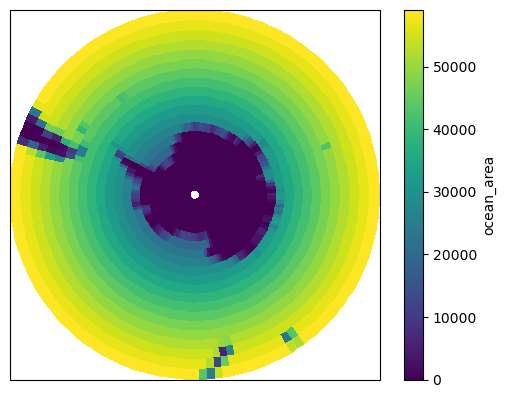

In [80]:
#(t): Each cell's ocean (km²)
era5_ocean_area_da = era5_day_grid_ds['ocean_area']
era5_ocean_area_da.plot(**POLAR);

In [ ]:
#(t): Check: the day's extent (million km²) on ERA5's own grid, and on the 2.5° grid counting each cell's ocean
(float(era5_point_area_da.where(100 * era5_day_ds['siconc'] >= THRESHOLD, 0).sum()) / 1e6,
 float(era5_ocean_area_da.where(100 * era5_day_grid_ds['siconc'] >= THRESHOLD, 0).sum()) / 1e6)

In [ ]:
#(t): ERA5's ocean saved, for Opening Data below
era5_ocean_area_path = SCRATCH_DIR / 'era5_ocean_area.zarr'
era5_ocean_area_da.to_dataset(name='ocean_area').to_zarr(era5_ocean_area_path, mode='w')
era5_ocean_area_path

In [ ]:
#(t): Where each year's store goes while the years are worked out, and the store they are joined into
era5_years_dir = MONTHLY_DIR / 'era5_siconc_years'
era5_monthly_path = MONTHLY_DIR / 'era5_siconc.zarr'
era5_years_dir, era5_monthly_path

In [ ]:
#(t): Years already done: saved as a year store (an interrupted run), or in the joined store
era5_done_years = [int(path.stem) for path in sorted(era5_years_dir.glob('*.zarr'))]
if era5_monthly_path.exists():
    era5_done_years += np.unique(xr.open_zarr(era5_monthly_path)['time'].dt.year).tolist()
era5_done_years

In [82]:
#(t): The years left, up to the end of historical
era5_todo_years = [year for year in range(1979, 2015) if year not in era5_done_years]
era5_todo_years

[]

In [ ]:
#(t): Each month's daily files at 00 UTC, for the years left
era5_month_paths = {(year, month): sorted(ERA5_RAW_DIR.glob(f'{year}/{month:02d}/*/*0000.ci.nc'))
                    for year in era5_todo_years for month in range(1, 13)}

In [ ]:
#(t): Check: one file for every day of every month (the months that have fewer or more: none)
{(year, month): len(month_paths) for (year, month), month_paths in era5_month_paths.items()
 if len(month_paths) != pd.Period(f'{year}-{month:02d}').days_in_month}

In [ ]:
%%time
#(t): Every month's mean on the workers (convert.era5_month_mean: the mean of its files, south of 38°S, summed in
#(t): float64); each year onto the grid (onto_grid), in %, and saved as soon as its twelve months are back
era5_futures = {year: [client.submit(convert.era5_month_mean, era5_month_paths[year, month], 'siconc', pure=False)
                       for month in range(1, 13)]
                for year in era5_todo_years}
for year in era5_todo_years:
    year_da = xr.DataArray(np.stack(client.gather(era5_futures[year])), dims=('time', 'latitude', 'longitude'),
                           coords={'time': pd.date_range(f'{year}-01-01', periods=12, freq='MS'),
                                   'latitude': era5_day_ds['latitude'], 'longitude': era5_day_ds['longitude']})
    year_grid_ds = onto_grid(year_da, era5_point_area_da, era5_day_ds['latitude'], era5_day_ds['longitude'])
    year_grid_da = 100 * year_grid_ds['siconc']
    year_path = era5_years_dir / f'{year}.zarr'
    year_grid_da.astype('float32').to_dataset(name='siconc').to_zarr(year_path, mode='w')
    logger.info(f'ERA5 {year} saved to {year_path}')

In [ ]:
#(t): The year stores, to be joined
era5_year_paths = sorted(era5_years_dir.glob('*.zarr'))
era5_year_paths

In [ ]:
#(t): Joined in time order, with the joined store of an earlier run if there is one
era5_parts_list = [xr.open_zarr(path)['siconc'] for path in era5_year_paths]
if era5_monthly_path.exists():
    era5_parts_list.insert(0, xr.open_zarr(era5_monthly_path)['siconc'])
era5_monthly_da = xr.concat(era5_parts_list, dim='time').sortby('time').load()
era5_monthly_da

In [ ]:
#(t): Check: every month once and in order, January 1979 to December 2014 (432 months)
era5_months_index = era5_monthly_da.indexes['time']
(era5_months_index.is_unique, era5_months_index.is_monotonic_increasing, str(era5_months_index[0]),
 str(era5_months_index[-1]), len(era5_months_index))

In [ ]:
#(t): Saved. Written as era5_siconc.zarr.part and renamed once complete, so a crash never leaves half a store under the
#(t): real name (the years left are worked out from it)
era5_monthly_part_path = era5_monthly_path.with_name(era5_monthly_path.name + '.part')
era5_monthly_da.to_dataset(name='siconc').to_zarr(era5_monthly_part_path, mode='w')
shutil.rmtree(era5_monthly_path, ignore_errors=True)
era5_monthly_part_path.rename(era5_monthly_path)
era5_monthly_path

In [ ]:
#(t): Check: the saved store reads back the same (largest difference, %)
float(abs(xr.open_zarr(era5_monthly_path)['siconc'] - era5_monthly_da).max())

In [ ]:
#(t): The year stores deleted, now that they are in the joined store
for path in era5_year_paths:
    shutil.rmtree(path)

### LESFMIP

#### What is on CEDA

In [56]:
#(t): The experiments looked for: notebook calc_01's, and hist-stratO3
CEDA_EXPERIMENTS = [*MAIN_EXPERIMENTS, *OZONE_NAMES]
CEDA_EXPERIMENTS

['hist-nat',
 'hist-aer',
 'hist-totalO3',
 'hist-GHG',
 'historical',
 'hist-stratO3']

In [ ]:
#(t): Every folder of the sea ice and of the cell areas of these models and experiments in CEDA_DIRS (the cell areas
#(t): also from piControl): one row per member and variable
ice_inventory_df = convert.ceda_inventory(MODELS, CEDA_EXPERIMENTS, CEDA_DIRS)
ice_inventory_df

In [59]:
#(t): The members used: CMIP6 only (CMIP6Plus's f2023 members have other forcing), monthly sea ice (SImon)
ice_members_df = ice_inventory_df.query('table == "SImon" and project == "CMIP6"')

In [ ]:
#(t): Check: CanESM5's hist-GHG members (10)
ice_members_df.query('model == "CanESM5" and experiment == "hist-GHG"')['member'].nunique()

In [61]:
#(t): siconc where a model has it for an experiment, else siconca ('siconc' sorts first, so it is the minimum)
ice_members_df = ice_members_df[ice_members_df['variable']
                                == ice_members_df.groupby(['model', 'experiment'])['variable'].transform('min')]

In [62]:
#(t): Only members that cover 1850 to the end of historical
ice_members_df = ice_members_df.query('start <= 1850 and end >= 2014')
ice_members_df

,project,activity,institution,model,experiment,member,table,variable,grid,n_files,start,end,folder
0,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r1i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
1,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r2i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
2,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r3i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
3,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r4i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
4,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r5i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,CMIP6,DAMIP,NCC,NorESM2-LM,hist-aer,r3i1p1f1,SImon,siconc,gn,18,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/NCC/NorESM2-LM/hi...
464,CMIP6,DAMIP,NCC,NorESM2-LM,hist-nat,r1i1p1f1,SImon,siconc,gn,18,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/NCC/NorESM2-LM/hi...
465,CMIP6,DAMIP,NCC,NorESM2-LM,hist-nat,r2i1p1f1,SImon,siconc,gn,18,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/NCC/NorESM2-LM/hi...
466,CMIP6,DAMIP,NCC,NorESM2-LM,hist-nat,r3i1p1f1,SImon,siconc,gn,18,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/NCC/NorESM2-LM/hi...


In [ ]:
#(t): Members on CEDA per model and experiment
ceda_member_counts_df = ice_members_df.pivot_table(index='model', columns='experiment', values='member',
                                                   aggfunc='nunique')
ceda_member_counts_df

In [ ]:
#(t): The sea-ice members on CEDA: each model (rows) and experiment (columns), grey where there are none
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.9 * ceda_member_counts_df.shape[1] + 0.5,
                                                  panel_height=0.4 * ceda_member_counts_df.shape[0] + 0.3, left_margin=1.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
counts_image = methods.plot_member_counts(ceda_member_counts_df, ax=axes[0, 0])
fig.colorbar(counts_image, ax=axes, location='bottom', shrink=0.6, label='Members')
fig.suptitle('Sea-ice members on CEDA', x=0.01, ha='left');

#### Example processing

What the loop below does for each store, on the first model and experiment. Nothing is saved here.

In [ ]:
#(t): One row per model and experiment: its variable and grid, and the store it goes to, named like notebook calc_01's
#(t): (hist-stratO3 saved as hist-totalO3)
ice_stores_df = ice_members_df.drop_duplicates(['model', 'experiment'])[['model', 'experiment', 'variable', 'grid']]
ice_stores_df['store_path'] = [
    LESFMIP_MONTHLY_DIR / f'{row.model}_siconc_{OZONE_NAMES.get(row.experiment, row.experiment)}_interp_monthly.zarr'
    for row in ice_stores_df.itertuples()]
ice_stores_df

In [ ]:
#(t): The first one
first_store = ice_stores_df.iloc[0]
first_store

In [598]:
#(t): Its members' rows in the inventory
first_rows_df = ice_members_df.query('model == @first_store.model and experiment == @first_store.experiment')
first_rows_df

,project,activity,institution,model,experiment,member,table,variable,grid,n_files,start,end,folder
0,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r1i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
1,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r2i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
2,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r3i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
3,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r4i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
4,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r5i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
5,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r6i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
6,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r7i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
7,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r8i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
8,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r9i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
9,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r10i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...


In [599]:
#(t): Each member's files (a member's record can be split over several files)
first_member_files = {row.member: sorted(Path(row.folder).glob('*.nc')) for row in first_rows_df.itertuples()}
first_member_files

{'r1i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r1i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r1i1p1f1_gn_185001-202012.nc')],
 'r2i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r2i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r2i1p1f1_gn_185001-202012.nc')],
 'r3i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r3i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r3i1p1f1_gn_185001-202012.nc')],
 'r4i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r4i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r4i1p1f1_gn_185001-202012.nc')],
 'r5i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r5i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r5i1p1f1_gn_185001-202012.nc')],
 'r6i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r6i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r

In [ ]:
#(t): Its grid's cell areas in the inventory: areacello for siconc (areacella for siconca). A model's cell areas are
#(t): the same in every run, so the first run that has them is used
first_area_variable = AREA_VARIABLES[first_store.variable]
first_area_rows_df = ice_inventory_df.query('model == @first_store.model and variable == @first_area_variable '
                                            'and grid == @first_store.grid')
first_area_rows_df

In [ ]:
#(t): The file in the first of those folders
first_area_path = sorted(Path(first_area_rows_df['folder'].iloc[0]).glob('*.nc'))[0]
first_area_path

In [ ]:
#(t): The cell areas (m²), on the sea ice's grid
first_area_ds = xr.open_dataset(first_area_path)
first_area_ds

In [602]:
#(t): The first member's files, opened together (lazily)
first_member, first_files = next(iter(first_member_files.items()))
first_member_ds = xr.open_mfdataset(first_files, combine='by_coords', data_vars='minimal', coords='minimal',
                                    compat='override')
first_member_ds

<xarray.Dataset> Size: 868MB
Dimensions:             (time: 2052, bnds: 2, j: 291, i: 360, vertices: 4)
Coordinates:
  * time                (time) object 16kB 1850-01-16 12:00:00 ... 2020-12-16...
  * j                   (j) int32 1kB 0 1 2 3 4 5 6 ... 285 286 287 288 289 290
  * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
    latitude            (j, i) float64 838kB dask.array<chunksize=(291, 360), meta=np.ndarray>
    longitude           (j, i) float64 838kB dask.array<chunksize=(291, 360), meta=np.ndarray>
    type                |S7 7B ...
Dimensions without coordinates: bnds, vertices
Data variables:
    time_bnds           (time, bnds) object 33kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    vertices_latitude   (j, i, vertices) float64 3MB dask.array<chunksize=(291, 360, 2), meta=np.ndarray>
    vertices_longitude  (j, i, vertices) float64 3MB dask.array<chunksize=(291, 360, 2), meta=np.ndarray>
    siconc              (time, j, i) float32 860MB dask.array<chunksize=(1, 291, 360), meta=np.ndarray>
Attributes: (53)

In [603]:
#(t): Only its sea ice, up to LAST_MONTH
first_siconc_ds = first_member_ds[[first_store.variable]].sel(time=slice(None, LAST_MONTH))

<xarray.Dataset> Size: 831MB
Dimensions:    (time: 1980, j: 291, i: 360)
Coordinates:
  * time       (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
  * j          (j) int32 1kB 0 1 2 3 4 5 6 7 ... 283 284 285 286 287 288 289 290
  * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
    latitude   (j, i) float64 838kB dask.array<chunksize=(291, 360), meta=np.ndarray>
    longitude  (j, i) float64 838kB dask.array<chunksize=(291, 360), meta=np.ndarray>
    type       |S7 7B ...
Data variables:
    siconc     (time, j, i) float32 830MB dask.array<chunksize=(1, 291, 360), meta=np.ndarray>
Attributes: (53)

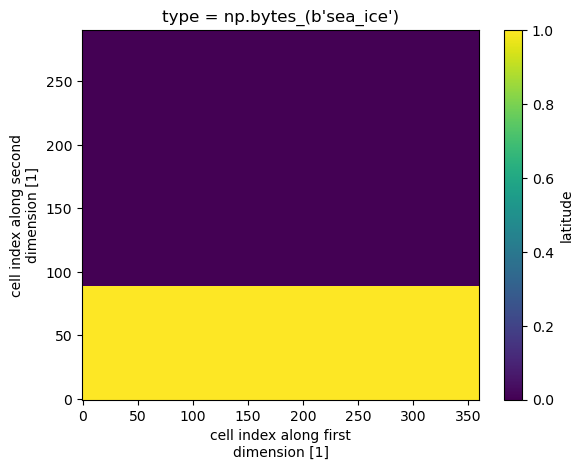

In [604]:
#(t): Which points are south of the grid's northern edge (38.75°S): True/False on (j, i), worked out now
first_lat_name, first_lon_name = POSITION_NAMES[first_store.variable]
first_south_points_da = (first_siconc_ds[first_lat_name] < -38.75).compute()
first_south_points_da.plot();

In [605]:
#(t): Only those points, read into memory (the files are global)
first_south_ds = first_siconc_ds.where(first_south_points_da, drop=True).load()
first_south_ds

<xarray.Dataset> Size: 254MB
Dimensions:    (time: 1980, j: 89, i: 360)
Coordinates:
  * time       (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
  * j          (j) int32 356B 0 1 2 3 4 5 6 7 8 9 ... 80 81 82 83 84 85 86 87 88
  * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
    latitude   (j, i) float64 256kB -78.39 -78.39 -78.39 ... -39.45 -39.45
    longitude  (j, i) float64 256kB 73.5 74.5 75.5 76.5 ... 69.5 70.5 71.5 72.5
    type       |S7 7B b'sea_ice'
Data variables:
    siconc     (time, j, i) float32 254MB nan nan nan nan ... 0.0 0.0 0.0 0.0
Attributes: (53)

In [607]:
%%time
#(t): The member on the 2.5° grid (file_onto_grid): what every member of every store below goes through
first_grid_ds = file_onto_grid(first_south_ds, first_area_ds, era5_ocean_area_da)
first_grid_ds

CPU times: user 973 ms, sys: 1.51 s, total: 2.48 s
Wall time: 2.54 s


<xarray.Dataset> Size: 23MB
Dimensions:     (member: 1, time: 1980, lat: 20, lon: 144)
Coordinates:
  * member      (member) object 8B 'r1i1p1f1'
  * time        (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    siconc      (member, time, lat, lon) float32 23MB nan nan nan ... 0.0 0.0
    ocean_area  (lat, lon) float32 12kB 0.0 0.0 0.0 ... 2.868e+04 5.031e+04

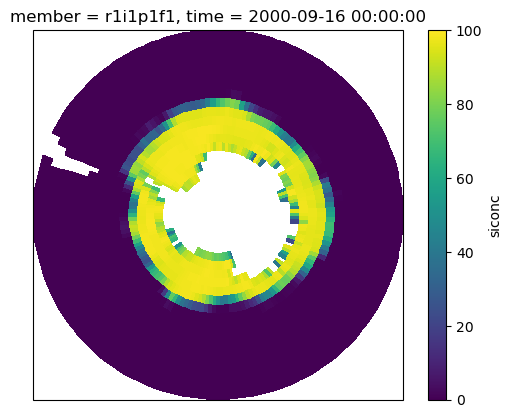

In [608]:
#(t): Quick look: its September 2000 on the 2.5° grid
first_grid_ds['siconc'].isel(member=0).sel(time='2000-09').squeeze('time').plot(vmin=0, vmax=100, **POLAR);

#### Processing full data and saving

Every store not made yet, one after the other: each member as in the steps above, one at a time, then the members side by side. If one fails, the loop stops with its error; save that one by hand without its broken members (as notebook calc_01, section 1 says) and run the loop again.

In [ ]:
#(t): Those not made yet
ice_todo_df = ice_stores_df[[not path.exists() for path in ice_stores_df['store_path']]]
ice_todo_df

In [ ]:
%%time
#(t): Each store as in the example above: each member onto the grid, one at a time, then the members side by side
#(t): (ocean_area once: it is the same for every member). Written as <store>.part and renamed once complete, so an
#(t): interrupted write is never taken for a finished store
for number, store in enumerate(ice_todo_df.itertuples(), start=1):
    rows_df = ice_members_df.query('model == @store.model and experiment == @store.experiment')
    logger.info(f'store {number} of {len(ice_todo_df)}: {store.model} {store.experiment}, {len(rows_df)} members')
    #(c): The cell areas of its grid, from the first run that has them
    area_variable = AREA_VARIABLES[store.variable]
    area_rows_df = ice_inventory_df.query('model == @store.model and variable == @area_variable and grid == @store.grid')
    area_ds = xr.open_dataset(sorted(Path(area_rows_df['folder'].iloc[0]).glob('*.nc'))[0])
    lat_name, lon_name = POSITION_NAMES[store.variable]
    member_grid_list = []
    for row in rows_df.itertuples():
        member_ds = xr.open_mfdataset(sorted(Path(row.folder).glob('*.nc')), combine='by_coords', data_vars='minimal',
                                      coords='minimal', compat='override')
        siconc_ds = member_ds[[store.variable]].sel(time=slice(None, LAST_MONTH))
        south_ds = siconc_ds.where(siconc_ds[lat_name] < -38.75, drop=True).load()
        member_grid_list.append(file_onto_grid(south_ds, area_ds, era5_ocean_area_da))
    store_ds = xr.concat(member_grid_list, dim='member', data_vars='minimal', coords='minimal', compat='override',
                         join='override')
    part_path = store.store_path.with_name(store.store_path.name + '.part')
    store_ds.chunk(member=5).to_zarr(part_path, mode='w', consolidated=True)
    part_path.rename(store.store_path)
    logger.info(f'saved {store.store_path}')

In [ ]:
#(t): Check: the members in each saved store minus those on CEDA (0 everywhere: none was lost)
ice_saved_counts_df = pd.Series({(row.model, row.experiment): xr.open_zarr(row.store_path).sizes['member']
                                 for row in ice_stores_df.itertuples()}).unstack()
ice_saved_counts_df - ceda_member_counts_df

In [ ]:
#(t): Check: the months in each saved store (1980 everywhere: January 1850 to December 2014)
pd.Series({(row.model, row.experiment): xr.open_zarr(row.store_path).sizes['time']
           for row in ice_stores_df.itertuples()}).unstack()

## Opening Data

First the file names, then each file opened.

### LESFMIP

In [ ]:
#(t): Where every model and experiment's monthly store would be
ice_files_df = pd.DataFrame([{'model': model, 'experiment': experiment,
                              'path': LESFMIP_MONTHLY_DIR / f'{model}_siconc_{experiment}_interp_monthly.zarr'}
                             for model in MODELS for experiment in MAIN_EXPERIMENTS])
ice_files_df

In [ ]:
#(t): Which of them exist
ice_files_df['exists'] = [path.exists() for path in ice_files_df['path']]
ice_files_df.pivot(index='model', columns='experiment', values='exists')

In [ ]:
#(t): The ones that exist
ice_found_df = ice_files_df[ice_files_df['exists']]
list(ice_found_df['path'])

In [56]:
#(t): Each store opened (lazily), named /<model>/<experiment>
ice_monthly_datasets = {f'{row.model}/{row.experiment}': xr.open_zarr(row.path, consolidated=True)
                        for row in ice_found_df.itertuples()}
ice_monthly_tree = xr.DataTree.from_dict(ice_monthly_datasets)
ice_monthly_tree

/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be suppor

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:     (time: 1980, member: 10, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * time        (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * member      (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │         * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│   │         * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │       Data variables:
│   │           siconc      (member, time, lat, lon) float32 228MB dask.array<chunksize=(5, 1980, 20, 144), meta=np.ndarray>
│   │           ocean_area  (lat, lon) float64 23kB dask.array<chunksize=(20, 144), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:     (lat: 20, time: 1980, member: 10, lon: 144)
│   │       Coordinates:
│   │         * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * time        (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│   │         * member      (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │       Data variables:
│   │           siconc      (member, time, lat, lon) float32 228MB dask.array<chunksize=(5, 1980, 20, 144), meta=np.ndarray>
│   │           ocean_area  (lat, lon) float64 23kB dask.array<chunksize=(20, 144), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:     (time: 1980, member: 10, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * time        (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * member      (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │         * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│   │       Data variables:
│   │           siconc      (member, time, lat, lon) float32 228MB dask.array<chunksize=(5, 1980, 20, 144), meta=np.ndarray>
│   │           ocean_area  (lat, lon) float64 23kB dask.array<chunksize=(20, 144), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:     (time: 1980, member: 10, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * time        (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│   │         * member      (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │         * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │       Data variables:
│   │           siconc      (member, time, lat, lon) float32 228MB dask.array<chunksize=(5, 1980, 20, 144), meta=np.ndarray>
│   │           ocean_area  (lat, lon) float64 23kB dask.array<chunksize=(20, 144), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:     (time: 1980, member: 35, lat: 20, lon: 144)
│           Coordinates:
│             * time        (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
│             * member      (member) object 280B 'r1i1p1f1' 'r1i1p2f1' ... 'r25i1p1f1'
│             * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│           Data variables:
│               siconc      (member, time, lat, lon) float32 798MB dask.array<chunksize=(5, 1980, 20, 144), meta=np.ndarray>
│               ocean_area  (lat, lon) float64 23kB dask.array<chunksize=(20, 144), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-aer
│   │       Dimensions:     (member: 5, time: 1980, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * member      (member) object 40B 'r1i1p1f1' 'r2i1p1f1' ... 

### ERA5

In [ ]:
#(t): ERA5's ocean in each cell (saved in Daily values to monthly means), and its monthly concentration
era5_ocean_area_path = SCRATCH_DIR / 'era5_ocean_area.zarr'
era5_monthly_path = MONTHLY_DIR / 'era5_siconc.zarr'
era5_ocean_area_path, era5_monthly_path

In [ ]:
#(t): ERA5's ocean in each cell (km²)
era5_ocean_area_da = xr.open_zarr(era5_ocean_area_path)['ocean_area'].load()
era5_ocean_area_da.plot(**POLAR);

In [ ]:
#(t): ERA5's monthly concentration (%) with each cell's ocean; small (5 MB), so read into memory
era5_monthly_ds = xr.open_zarr(era5_monthly_path)
era5_ice_ds = xr.merge([era5_monthly_ds, era5_ocean_area_da]).load()
era5_ice_ds

### What was opened

Whichever section ran. First how many members each model has for each experiment: an empty square is a store that was never opened.

In [ ]:
#(t): Members per model (rows) and experiment (columns)
ice_member_counts_df = pd.Series({(node.parent.name, node.name): node.sizes['member']
                                  for node in ice_monthly_tree.leaves}).unstack()
ice_member_counts_df = ice_member_counts_df.reindex(index=MODELS, columns=MAIN_EXPERIMENTS)
ice_member_counts_df

In [ ]:
#(t): The sea-ice members opened: each model (rows) and experiment (columns), grey where there are none
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.9 * ice_member_counts_df.shape[1] + 0.5,
                                                  panel_height=0.4 * ice_member_counts_df.shape[0] + 0.3, left_margin=1.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
counts_image = methods.plot_member_counts(ice_member_counts_df, ax=axes[0, 0])
fig.colorbar(counts_image, ax=axes, location='bottom', shrink=0.6, label='Members')
fig.suptitle('Sea-ice members opened', x=0.01, ha='left');

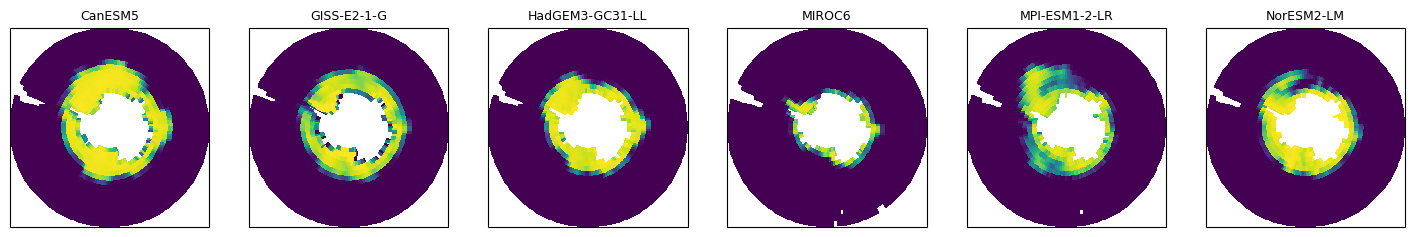

In [106]:
#(t): Quick look: every model's first historical member in September 2013
fig, axes = plt.subplots(1, len(MODELS), figsize=(3 * len(MODELS), 3.2),
                         subplot_kw=dict(projection=ccrs.SouthPolarStereo()))
for ax, model in zip(axes, MODELS):
    if model in ice_monthly_tree.children and 'historical' in ice_monthly_tree[model].children:
        field_da = ice_monthly_tree[model]['historical']['siconc'].isel(member=0).sel(time='2013-09').squeeze('time')
        field_da.plot(ax=ax, transform=ccrs.PlateCarree(), vmin=0, vmax=100, add_colorbar=False)
    ax.set_title(model, fontsize=9)

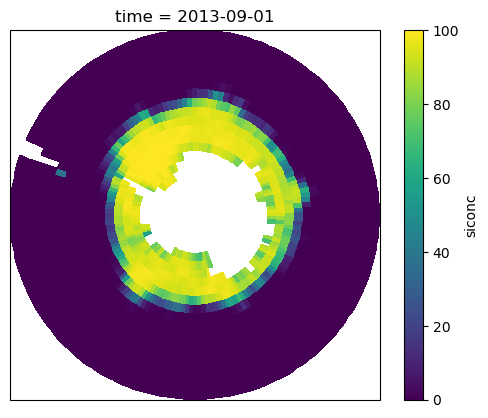

In [107]:
#(t): ... and ERA5's
era5_ice_ds['siconc'].sel(time='2013-09').squeeze('time').plot(vmin=0, vmax=100, **POLAR);

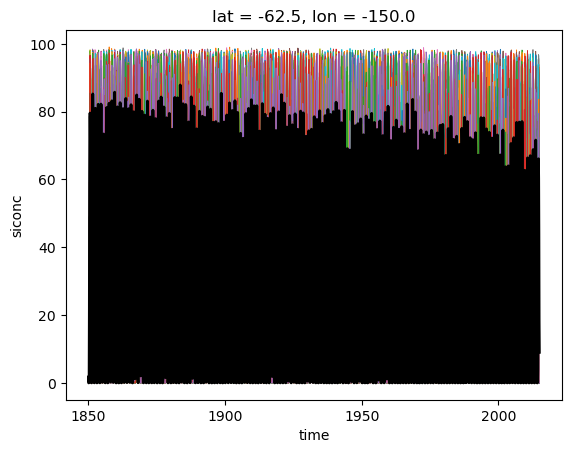

In [108]:
#(t): Quick look: EXAMPLE_MODEL's historical members at one cell near the ice edge, every month
point_da = ice_monthly_tree[EXAMPLE_MODEL]['historical']['siconc'].sel(lat=-62.5, lon=-150)
point_da.plot.line(x='time', hue='member', add_legend=False, lw=0.6)
point_da.mean('member').plot.line(x='time', color='k', lw=2);

## 3. Seasonal Means

Each record is cut at `LAST_MONTH`, then averaged into seasons by `pp.seasonal_means`: DJF is labelled by the year of its December, and only complete seasons in whole years are kept, as for the temperature in notebook calc_01.

In [109]:
#(t): Every record cut where historical ends
ice_monthly_cut_tree = ice_monthly_tree.sel(time=slice(None, LAST_MONTH))

In [110]:
#(t): Every member's seasonal means (%), on (member, year, season, lat, lon), lazily
ice_season_tree = xr.DataTree.from_dict({node.path: xr.Dataset({'siconc': pp.seasonal_means(node['siconc'])})
                                         for node in ice_monthly_cut_tree.leaves})
ice_season_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (year: 164, season: 4, member: 10, lon: 144, lat: 20)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │       Data variables:
│   │           siconc   (member, lat, lon, year, season) float32 76MB dask.array<chunksize=(5, 20, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (year: 164, season: 4, lat: 20, lon: 144, member: 10)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │       Data variables:
│   │           siconc   (member, lat, lon, year, season) float32 76MB dask.array<chunksize=(5, 20, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (year: 164, season: 4, member: 10, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │       Data variables:
│   │           siconc   (member, lat, lon, year, season) float32 76MB dask.array<chunksize=(5, 20, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (year: 164, season: 4, lon: 144, member: 10, lat: 20)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │       Data variables:
│   │           siconc   (member, lat, lon, year, season) float32 76MB dask.array<chunksize=(5, 20, 144, 164, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (year: 164, season: 4, member: 35, lat: 20, lon: 144)
│           Coordinates:
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 280B 'r1i1p1f1' 'r1i1p2f1' ... 'r25i1p1f1'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│           Data variables:
│               siconc   (member, lat, lon, year, season) float32 264MB dask.array<chunksize=(5, 20, 144, 164, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-aer
│   │       Dimensions:  (year: 164, season: 4, member: 5, lon: 144, lat: 20)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (mem

In [ ]:
#(t): Check: every record's first and last year (with the full data, 1850 and 2013 everywhere: DJF 2014 would need
#(t): January and February 2015)
pd.Series({node.path: (int(node['year'][0]), int(node['year'][-1])) for node in ice_season_tree.leaves})

In [111]:
#(t): ERA5's seasonal concentration (%), on (year, season, lat, lon)
era5_ice_season_ds = pp.seasonal_means(era5_ice_ds[['siconc']])
era5_ice_season_da = era5_ice_season_ds['siconc']
era5_ice_season_da

<xarray.DataArray 'siconc' (lat: 20, lon: 144, year: 35, season: 4)> Size: 2MB
dask.array<chunksize=(10, 72, 35, 4), meta=np.ndarray>
Coordinates:
  * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
  * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0

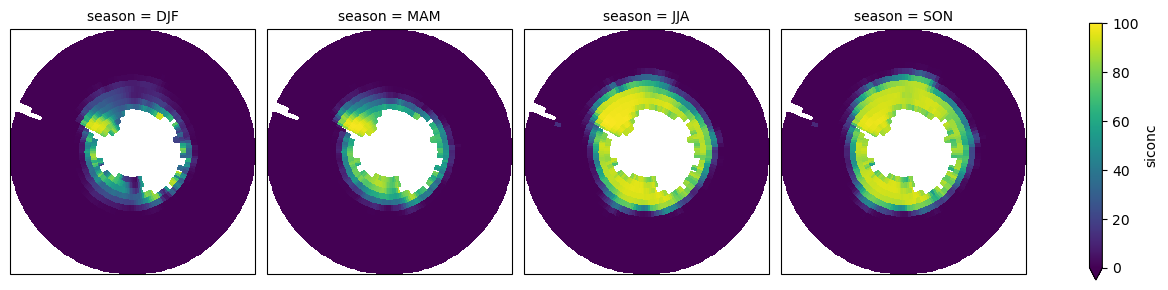

In [112]:
#(t): Its mean over SATELLITE_YEAR_RANGE
era5_climatology_da = era5_ice_season_da.sel(year=SATELLITE_YEAR_RANGE).mean('year')
era5_climatology_da.sel(season=SEASONS).plot(col='season', vmin=0, vmax=100, **POLAR);

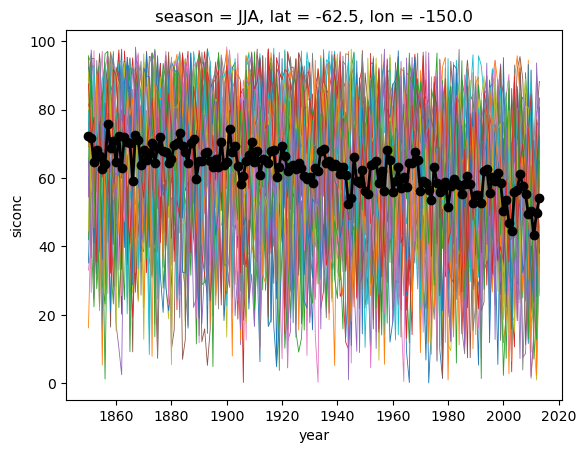

In [113]:
#(t): Quick look: EXAMPLE_MODEL's historical members at one cell near the ice edge in JJA (black: their mean)
point_jja_da = ice_season_tree[EXAMPLE_MODEL]['historical']['siconc'].sel(season='JJA').sel(lat=-62.5, lon=-150)
point_jja_da.plot.line(x='year', hue='member', add_legend=False, lw=0.6)
point_jja_da.mean('member').plot.line(x='year', color='k', lw=2, marker='o');

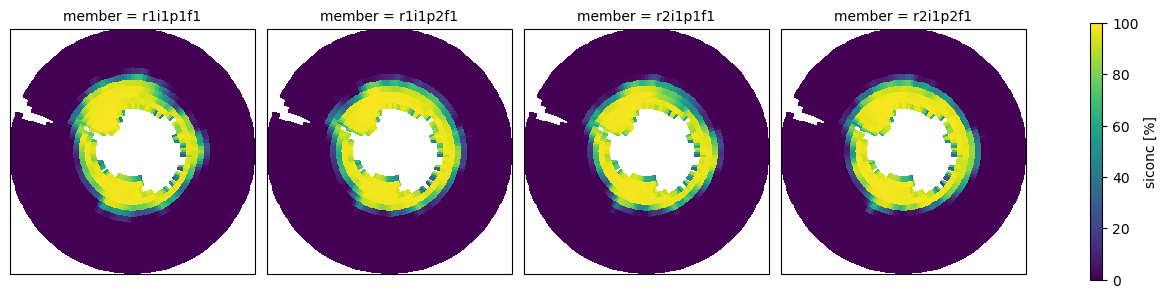

In [114]:
#(t): Quick look: four of EXAMPLE_MODEL's historical members in JJA of the last year
ice_season_tree[EXAMPLE_MODEL]['historical']['siconc'].isel(year=-1, member=slice(0, 4)).sel(season='JJA').plot(
    col='member', vmin=0, vmax=100, **POLAR);

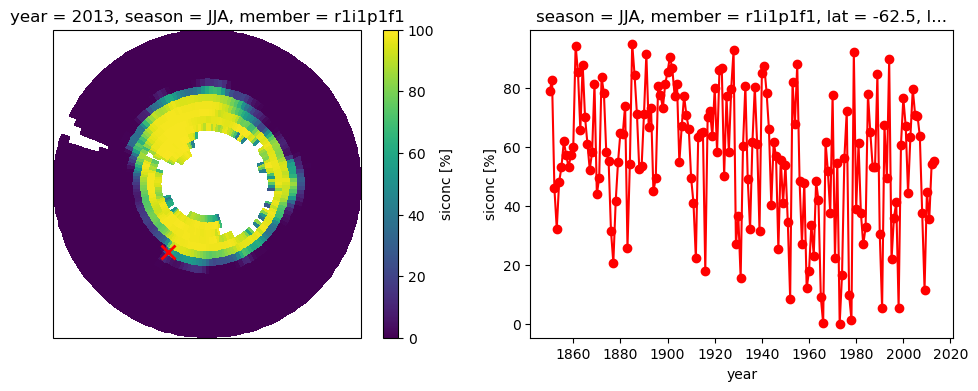

In [115]:
#(t): Quick look: a map and the time series behind it. EXAMPLE_MODEL's first historical member in JJA: the last year's
#(t): map
#(t): with one cell marked, and every year at that cell
jja_da = ice_season_tree[EXAMPLE_MODEL]['historical']['siconc'].isel(member=0).sel(season='JJA')
fig = plt.figure(figsize=(12, 4))
ax_map = fig.add_subplot(1, 2, 1, projection=ccrs.SouthPolarStereo())
jja_da.isel(year=-1).plot(ax=ax_map, transform=ccrs.PlateCarree(), vmin=0, vmax=100)
ax_map.plot(-150, -62.5, 'rx', ms=10, mew=2, transform=ccrs.PlateCarree())
ax_series = fig.add_subplot(1, 2, 2)
jja_da.sel(lat=-62.5, lon=-150).plot.line(ax=ax_series, x='year', color='r', marker='o');

## 4. Extent and Ice Edge

The **extent** is the ocean area of the cells with at least 15% ice. On the 2.5° grid a coastal cell is part land, so each cell counts only its ocean (`ocean_area`, from section 1); the rest of the cells south of 60°S is the continent.

First on one field, step by step.

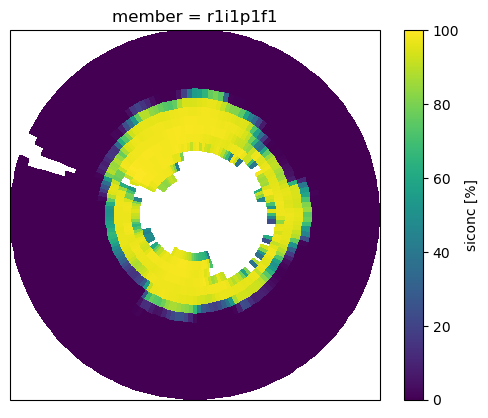

In [116]:
#(t): One field: EXAMPLE_MODEL's first historical member in September 2013 (%)
example_siconc_da = ice_monthly_tree[EXAMPLE_MODEL]['historical']['siconc'].isel(member=0).sel(time='2013-09')
example_siconc_da = example_siconc_da.squeeze('time', drop=True).load()
example_siconc_da.plot(vmin=0, vmax=100, **POLAR);

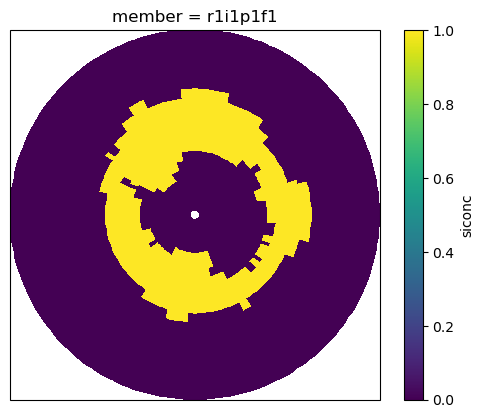

In [117]:
#(t): The cells that count as ice: at least THRESHOLD (15%)
example_ice_cells_da = example_siconc_da >= THRESHOLD
example_ice_cells_da.plot(**POLAR);

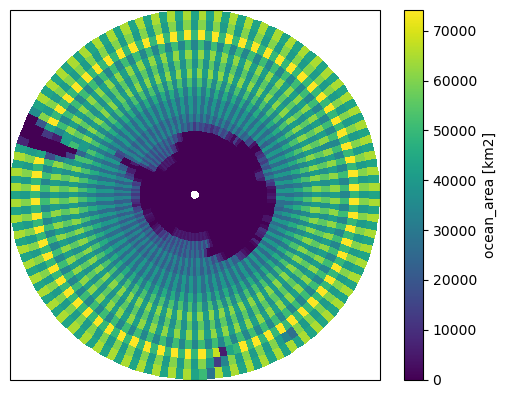

In [118]:
#(t): Each cell's ocean (km²), saved with the store
example_ocean_area_da = ice_monthly_tree[EXAMPLE_MODEL]['historical']['ocean_area'].load()
example_ocean_area_da.plot(**POLAR);

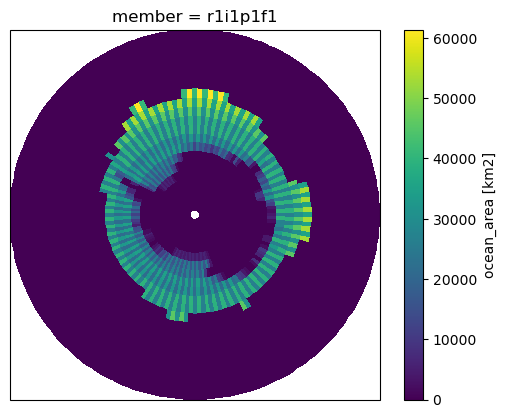

In [119]:
#(t): The ice-covered ocean of each cell (km²): its ocean where it is ice, 0 elsewhere
example_ice_area_da = example_ocean_area_da.where(example_ice_cells_da, 0)
example_ice_area_da.plot(**POLAR);

In [120]:
#(t): The extent: their sum (million km²)
example_extent = float(example_ice_area_da.sum()) / 1e6
example_extent

20.950729852661134

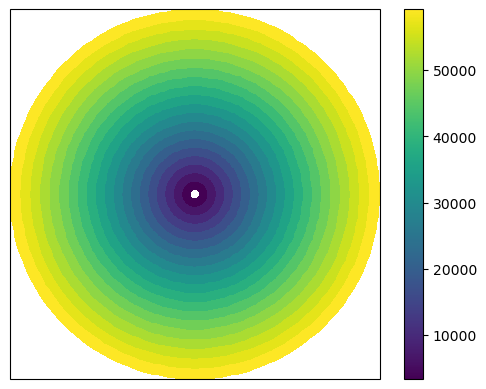

In [121]:
#(t): Each 2.5° cell's whole area (km², section 1), the same for every model and ERA5
grid_cell_area_da.plot(**POLAR);

In [ ]:
#(t): The land in each cell (km²): its area less its ocean
#(c): A little below 0 in the few cells whose ocean share is over 1 (section 1). That doesn't matter for the
#(c): continent: summed south of 60°S, it is that band's whole area less its ocean
example_land_area_da = grid_cell_area_da - example_ocean_area_da
example_land_area_da.plot(**POLAR);

In [123]:
#(t): The continent (million km²): the land south of 60°S (islands further north are not part of the ice edge)
example_continent_area = float(example_land_area_da.where(example_land_area_da['lat'] <= -60).sum()) / 1e6
example_continent_area

14.405535118812526

The same steps as one function, for every member and month of a model's experiment.

In [ ]:
#(t): The steps above for one model's experiment
#(c): skip_empty: nodes with no data (the root, each model's node) are passed through unchanged
@skip_empty
def monthly_extent(ds):
    """The extent of every member and month, and the continent's area.

    Args:
        ds (xr.Dataset): siconc (%) on ([member,] time, lat, lon), and ocean_area (km²) on (lat, lon)

    Returns:
        xr.Dataset: extent (km²) on ([member,] time), and continent_area (km²), one number
    """
    #(c): The ice-covered ocean of each cell: its ocean where it has at least THRESHOLD %, 0 elsewhere
    ice_cells_da = ds['siconc'] >= THRESHOLD
    ice_area_da = ds['ocean_area'].where(ice_cells_da, 0)
    #(c): The extent: their sum
    extent_da = ice_area_da.sum(['lat', 'lon'])
    #(c): The continent: each cell's area less its ocean, summed south of 60°S
    land_area_da = grid_cell_area_da - ds['ocean_area']
    continent_area_da = land_area_da.where(land_area_da['lat'] <= -60).sum(['lat', 'lon'])
    return xr.Dataset({'extent': extent_da, 'continent_area': continent_area_da})

In [ ]:
#(t): Example: EXAMPLE_MODEL's historical, every member and month
example_extent_ds = monthly_extent(ice_monthly_tree[EXAMPLE_MODEL]['historical'].to_dataset()).compute()
example_extent_ds

In [ ]:
#(t): Check: the first member's September 2013 and the continent are those of the steps above (million km²)
(float(example_extent_ds['extent'].isel(member=0).sel(time='2013-09').squeeze()) / 1e6, example_extent,
 float(example_extent_ds['continent_area']) / 1e6, example_continent_area)

In [ ]:
#(t): Quick look: the steps on the field above (top), and the same member's extent from monthly_extent, every month
#(t): (bottom)
fig = plt.figure(figsize=(12, 8))
gs = GridSpec(2, 4)
upper_axes = [fig.add_subplot(gs[0, i], projection=ccrs.SouthPolarStereo()) for i in range(4)]

example_siconc_da.plot(ax=upper_axes[0], transform=ccrs.PlateCarree())
upper_axes[0].set_title('siconc (%)')

example_ice_cells_da.plot(ax=upper_axes[1], transform=ccrs.PlateCarree())
upper_axes[1].set_title(f'siconc >= {THRESHOLD}')

example_ice_area_da.plot(ax=upper_axes[2], transform=ccrs.PlateCarree())
upper_axes[2].set_title('ice area (km²)')

example_land_area_da.plot(ax=upper_axes[3], transform=ccrs.PlateCarree())
upper_axes[3].set_title('land area (km²)')

time_ax = fig.add_subplot(gs[1, :])
(example_extent_ds['extent'].isel(member=0) / 1e6).plot(ax=time_ax)
time_ax.set_title('extent (million km²)');

In [162]:
%%time
#(t): Every model and experiment
ice_monthly_extent_tree = ice_monthly_tree.map_over_datasets(monthly_extent).compute()
ice_monthly_extent_tree

CPU times: user 340 ms, sys: 14.3 ms, total: 354 ms
Wall time: 2.54 s


<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:         (time: 1980, member: 10)
│   │       Coordinates:
│   │         * time            (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:...
│   │         * member          (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │       Data variables:
│   │           extent          (member, time) float64 158kB 1.3e+07 8.534e+06 ... 1.636e+07
│   │           continent_area  float64 8B 1.441e+07
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:         (time: 1980, member: 10)
│   │       Coordinates:
│   │         * time            (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:...
│   │         * member          (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │       Data variables:
│   │           extent          (member, time) float64 158kB 1.285e+07 ... 1.817e+07
│   │           continent_area  float64 8B 1.441e+07
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:         (time: 1980, member: 10)
│   │       Coordinates:
│   │         * time            (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:...
│   │         * member          (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │       Data variables:
│   │           extent          (member, time) float64 158kB 1.284e+07 ... 1.573e+07
│   │           continent_area  float64 8B 1.441e+07
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:         (time: 1980, member: 10)
│   │       Coordinates:
│   │         * time            (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:...
│   │         * member          (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│   │       Data variables:
│   │           extent          (member, time) float64 158kB 1.293e+07 ... 1.595e+07
│   │           continent_area  float64 8B 1.441e+07
│   └── Group: /CanESM5/historical
│           Dimensions:         (time: 1980, member: 35)
│           Coordinates:
│             * time            (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:...
│             * member          (member) object 280B 'r1i1p1f1' 'r1i1p2f1' ... 'r25i1p1f1'
│           Data variables:
│               extent          (member, time) float64 554kB 1.297e+07 ... 1.512e+07
│               continent_area  float64 8B 1.441e+07
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-aer
│   │       Dimensions:         (member: 5, time: 1980)
│   │       Coordinates:
│   │         * member          (member) object 40B 'r1i1p1f1' 'r2i1p1f1' ... 'r5i1p1f1'
│   │         * time            (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:...
│   │       Data variables:
│   │           extent          (member, time) float64 79kB 3.472e+06 ... 1.021e+07
│   │           continent_area  float64 8B 1.408e+07
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:         (time: 1980, member: 5)
│   │       Coordinates:
│   │         * time            (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:...
│   │         * member          (member) object 40B 'r1i1p1f1' 'r2i1p1f1' ... 'r5i1p1f1'
│   │       Data variables:
│   │           extent          (member, time) float64 79kB 3.472e+06 ... 1.051e+07
│   │           continent_area  float64 8B 1.408e+07
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:         (member: 10, time: 1980)
│           Coordinates:
│             * member          (member) object 80B 'r1i1p1f1' 'r2i1p1f1' ... 'r10i1p1f1'
│             * time            (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:...
│           Data variables:
│               extent          (member, time) float64 158kB 3.442e+06 1.5e+06 ... 9.961e+06
│               continent_area  float64 8B 1.408e+07
├── Group: /HadGEM3-GC31-LL
│   ├── Group: /HadGEM3-GC31-LL/hist-nat
│   │       Dimensions:         (member: 60, time: 1980)
│   │       Coordinates:
│   │         * member          (me

In [ ]:
#(t): Quick look: EXAMPLE_MODEL's historical members' extent, every month (million km²)
(ice_monthly_extent_tree[EXAMPLE_MODEL]['historical']['extent'] / 1e6).plot.line(x='time', hue='member',
                                                                                 add_legend=False, lw=0.5);

In [ ]:
#(t): Quick look: every model's continent (million km²; the grids' coasts differ a little)
continent_area_ds = tree_to_dataset(ice_monthly_extent_tree.isel(member=0, time=0, drop=True),
                                    dims=['model', 'experiment'])
(continent_area_ds['continent_area'] / 1e6).to_pandas().plot.bar(rot=45, ylabel='million km²');

### Seasonal extent

In [ ]:
#(t): Every record cut where historical ends
ice_monthly_extent_cut_tree = ice_monthly_extent_tree.sel(time=slice(None, LAST_MONTH))

In [ ]:
#(t): Every member's monthly extent averaged into seasons (as the concentration in section 3), on (member, year, season),
#(t): and its model's continent (km²)
ice_extents_tree = xr.DataTree.from_dict({node.path: xr.Dataset({'extent': pp.seasonal_means(node['extent']),
                                                                 'continent_area': node['continent_area']})
                                          for node in ice_monthly_extent_cut_tree.leaves})
ice_extents_tree

In [ ]:
#(t): Quick look: EXAMPLE_MODEL's historical members in DJF (million km²)
(ice_extents_tree[EXAMPLE_MODEL]['historical']['extent'].sel(season='DJF') / 1e6).plot.line(x='year', hue='member',
                                                                                            add_legend=False);

In [ ]:
#(t): Quick look: EXAMPLE_MODEL's first historical member, every season (million km²)
(ice_extents_tree[EXAMPLE_MODEL]['historical']['extent'].isel(member=0) / 1e6).plot.line(x='year', hue='season');

In [ ]:
#(t): Saved (notebooks plot_03 and plot_06 read it too)
extent_path = RESULTS_DIR / 'extent.zarr'
ice_extents_tree.to_zarr(extent_path, mode='w')
extent_path

### Ice edge on the maps

The 15% line of the ensemble-mean concentration over each experiment's final `WINDOW` years.

In [ ]:
#(t): Each experiment's final WINDOW years of seasonal concentration
ice_final_season_tree = ice_season_tree.isel(year=slice(-WINDOW, None))

In [ ]:
#(t): The ensemble mean over them (%)
ice_final_mean_tree = ice_final_season_tree.mean(['year', 'member'])

In [ ]:
%%time
#(t): In one DataArray, on (model, experiment, season, lat, lon)
ice_climatology_ds = tree_to_dataset(ice_final_mean_tree, dims=['model', 'experiment']).compute()
ice_climatology_da = ice_climatology_ds['siconc'].transpose('model', 'experiment', ...)
ice_climatology_da

In [ ]:
#(t): Quick look: hist-nat's, every model and season
ice_climatology_da.sel(experiment='hist-nat', season=SEASONS).plot(row='model', col='season', vmin=0, vmax=100, **POLAR);

In [ ]:
#(t): Saved (notebooks plot_03 and plot_06 read it too)
climatology_path = RESULTS_DIR / 'climatology.zarr'
ice_climatology_da.to_dataset(name='siconc').to_zarr(climatology_path, mode='w')
climatology_path

In [ ]:
#(t): Each cell's ocean, every model and experiment, on (model, experiment, lat, lon), for plot_02's figure of the edge
ocean_area_ds = tree_to_dataset(ice_monthly_tree.isel(member=0, time=0, drop=True),
                                dims=['model', 'experiment'])[['ocean_area']].compute()
ocean_area_ds

In [ ]:
#(t): Saved
ocean_area_path = RESULTS_DIR / 'ocean_area.zarr'
ocean_area_ds.to_zarr(ocean_area_path, mode='w')
ocean_area_path

### Ice edge as an equivalent latitude

On a zonal mean the edge is an **equivalent latitude** (Bracegirdle et al., 2024): the latitude whose polar cap holds the extent and the continent together. The cap south of latitude φ has area 2πR²(1 + sin φ), so φ = arcsin(area / 2πR² − 1).

In [ ]:
#(t): Each member's extent over each experiment's final WINDOW years
ice_final_extents_tree = ice_extents_tree.isel(year=slice(-WINDOW, None))

In [ ]:
#(t): Their ensemble mean (km²), and each model's continent
ice_final_mean_extent_tree = ice_final_extents_tree.mean(['member', 'year'])

In [ ]:
#(t): In one Dataset, on (model, experiment, season)
ice_final_ds = tree_to_dataset(ice_final_mean_extent_tree, dims=['model', 'experiment'])

In [ ]:
#(t): The area of the cap: the extent and the continent (km²)
ice_cap_area_da = ice_final_ds['extent'] + ice_final_ds['continent_area']

In [ ]:
#(t): The latitude whose cap has that area (degrees)
hemisphere_area = 2 * np.pi * EARTH_RADIUS ** 2
ice_edges_da = np.rad2deg(np.arcsin(ice_cap_area_da / hemisphere_area - 1))
ice_edges_da

In [ ]:
#(t): Quick look: each model's edge in each experiment
ice_edges_da.sel(season=SEASONS).plot.line(x='season', hue='experiment', col='model', marker='o');

In [ ]:
#(t): Saved
edge_latitude_path = RESULTS_DIR / 'edge_latitude.zarr'
ice_edges_da.to_dataset(name='edge_latitude').to_zarr(edge_latitude_path, mode='w')
edge_latitude_path

### Ice edge at each longitude

Along each longitude, going south from 40°S, the edge is where the first cell without ice is followed by a cell with ice (at least `THRESHOLD`), on the line between the two; land is skipped. Every historical member each year and season, and ERA5.

In [ ]:
#(t): The edge along one longitude
def _get_edge_latitude(arr, lats):
    """The latitude where the ice starts, going south along one column of cells.

    Args:
        arr (np.ndarray): 1 where a cell has ice, 0 where it doesn't, NaN on land; south to north
        lats (np.ndarray): the cells' centre latitudes, south to north

    Returns:
        float: the southern side of the first ice-free cell that has an ice cell to its south (degrees); NaN if none
    """
    #(c): North to south
    arr, lats = arr[::-1], lats[::-1]
    #(c): Land left out, so the cells either side of it become neighbours
    ok = ~np.isnan(arr)
    arr, lats = arr[ok], lats[ok]
    #(c): Where a cell without ice (0) is followed by one with ice (1)
    idx = np.flatnonzero(np.diff(arr) == 1)
    #(c): The first such pair from the north: the line between them, half a cell (1.25°) south of the ice-free one
    return (lats[idx[0]] - 2.5/2) if idx.size else np.nan

In [ ]:
#(t): Check on a made-up column, south to north: ice at 70°S and 67.5°S, none at 65°S and 62.5°S. The edge is between
#(t): 67.5°S and 65°S: −66.25
_get_edge_latitude(np.array([1.0, 1.0, 0.0, 0.0]), np.array([-70.0, -67.5, -65.0, -62.5]))

In [ ]:
#(t): The edge at every longitude
def get_edge_latitude(da):
    """_get_edge_latitude along lat, at every longitude (and member, year and season).

    Args:
        da (xr.DataArray | xr.Dataset): concentration (%) with a lat dim, NaN on land

    Returns:
        The same without lat: the edge's latitude (degrees), keeping the concentration's name
    """
    #(c): 1 where a cell has ice (at least THRESHOLD %), 0 where it doesn't, NaN on land
    nan_mask = np.isnan(da)
    da = xr.where(~nan_mask, da >= THRESHOLD, np.nan)
    #(c): One column of cells along lat at a time
    edge_da = xr.apply_ufunc(
        _get_edge_latitude,
        da,
        input_core_dims = [['lat']],
        output_core_dims = [[]],
        dask='parallelized',
        vectorize=True,
        output_dtypes=[float],
        kwargs = dict(lats = da.lat.values),
        dask_gufunc_kwargs = dict(allow_rechunk=True)
    )

    return edge_da

In [ ]:
#(t): Example: the edge of section 4's field (September 2013, EXAMPLE_MODEL's first historical member) at each longitude
example_edge_da = get_edge_latitude(example_siconc_da)
example_edge_da

In [ ]:
#(t): Quick look: the field, and its edge (black dots)
fig, ax = plt.subplots(subplot_kw=dict(projection=ccrs.SouthPolarStereo()))
example_siconc_da.plot(ax=ax, transform=ccrs.PlateCarree(), vmin=0, vmax=100)
ax.plot(example_edge_da['lon'], example_edge_da, 'k.', transform=ccrs.PlateCarree());

In [ ]:
#(t): Every historical member's edge, each year and season (the variable keeps the concentration's name, siconc)
ice_edge_model_tree = xr.map_over_datasets(skip_empty(get_edge_latitude), ice_season_tree.match('*/historical')).compute()
ice_edge_model_tree

In [ ]:
#(t): ERA5's, each year and season
era5_edge_lat_da = get_edge_latitude(era5_ice_season_da)
era5_edge_lat_da

In [ ]:
#(t): Kilometres per degree of latitude (about 111.2)
KM_PER_DEG_LAT = np.pi * EARTH_RADIUS / 180

In [ ]:
#(t): EXAMPLE_MODEL's historical members' edges (degrees)
model_edge_lat_da = ice_edge_model_tree[EXAMPLE_MODEL]['historical']['siconc']

In [ ]:
#(t): How far north of each member's edge ERA5's is (km; negative: ERA5's is further south), over the years both have
edge_offset_km_da = (era5_edge_lat_da - model_edge_lat_da) * KM_PER_DEG_LAT
edge_offset_km_da

In [ ]:
#(t): Quick look: EXAMPLE_MODEL's members' edges in DJF, one year at a time (move the slider)
model_edge_djf_da = model_edge_lat_da.sel(season='DJF')

@w.interact(i=w.IntSlider(0, 0, model_edge_djf_da.sizes['year'] - 1))
def show(i):
    """Draw every member's edge in year i, the slider's position."""
    model_edge_djf_da.isel(year=i).plot(hue='member', add_legend=False)
    plt.title(str(model_edge_djf_da.year[i].values))
    plt.ylim(-75, -50)

In [ ]:
#(t): EXAMPLE_MODEL's ensemble-mean edge
model_edge_mean_da = model_edge_lat_da.mean('member')

In [ ]:
#(t): Quick look in JJA, every year from 1979 (blue to red): EXAMPLE_MODEL's ensemble-mean edge (top left), ERA5's (top
#(t): right),
#(t): and ERA5's minus EXAMPLE_MODEL's (bottom)
season = 'JJA'
model_season_edge_da = model_edge_mean_da.sel(year=slice(era5_edge_lat_da.year.values[0], None)).sel(season=season)
era5_season_edge_da = era5_edge_lat_da.sel(season=season)
season_edge_diff_da = era5_season_edge_da - model_season_edge_da
year_color_list = plt.get_cmap('RdBu_r')(np.linspace(0, 1, model_season_edge_da.sizes['year']))

fig = plt.figure(figsize=(12, 6))
gs = GridSpec(2, 2)
axes_top = [fig.add_subplot(gs[0, i]) for i in range(2)]
axes_bottom = fig.add_subplot(gs[1, :])

for i, year in enumerate(model_season_edge_da.year.values):
    model_season_edge_da.sel(year=year).plot(ax=axes_top[0], color=year_color_list[i], alpha=0.3)
    era5_season_edge_da.sel(year=year).plot(ax=axes_top[1], color=year_color_list[i], alpha=0.3)
    season_edge_diff_da.sel(year=year).plot(ax=axes_bottom, color=year_color_list[i], alpha=0.3)

In [ ]:
#(t): Quick look: ERA5's edge minus each model's ensemble mean (km; positive: ERA5's further north) at each longitude,
#(t): every model (rows) and season (columns), every year from 1979 (blue to red)
model_names = list(ice_edge_model_tree.children)
first_era5_year = era5_edge_lat_da.year.values[0]

year_cmap = plt.get_cmap('RdBu_r')
year_norm = mpl.colors.Normalize(vmin=era5_edge_lat_da.year.min().item(), vmax=era5_edge_lat_da.year.max().item())

fig, axes = plt.subplots(len(model_names), len(SEASONS), figsize=(3.5 * len(SEASONS), 2.2 * len(model_names)),
                         sharex=True, sharey=True, squeeze=False, layout='constrained')

for row, model_name in enumerate(model_names):
    model_edge_lat_mean_da = (ice_edge_model_tree[model_name]['historical']['siconc']
                              .mean('member')
                              .sel(year=slice(first_era5_year, None)))
    model_edge_offset_km_da = (era5_edge_lat_da - model_edge_lat_mean_da) * KM_PER_DEG_LAT
    for col, season in enumerate(SEASONS):
        ax = axes[row, col]
        season_offset_km_da = model_edge_offset_km_da.sel(season=season)
        for year in season_offset_km_da.year.values:
            ax.plot(season_offset_km_da.lon, season_offset_km_da.sel(year=year),
                    color=year_cmap(year_norm(year)), alpha=0.3)
        ax.axhline(0, color='k', lw=0.6)
        ax.set_title(season if row == 0 else '')
        ax.set_ylabel(f'{model_name}\n(km)' if col == 0 else '')
        if row == len(model_names) - 1:
            ax.set_xlabel('lon')

year_mappable = mpl.cm.ScalarMappable(norm=year_norm, cmap=year_cmap)
fig.colorbar(year_mappable, ax=axes, label='year', shrink=0.6);

In [ ]:
#(t): Saved
ice_edge_model_path = RESULTS_DIR / 'ice_edge_model_tree.zarr'
ice_edge_model_tree.to_zarr(ice_edge_model_path, mode='w')
ice_edge_model_path

In [ ]:
#(t): Saved (as siconc, its name)
era5_edge_lat_path = RESULTS_DIR / 'ice_edge_lat_era5.zarr'
era5_edge_lat_da.to_dataset().to_zarr(era5_edge_lat_path, mode='w')
era5_edge_lat_path

## 5. Comparison with ERA5

ERA5 counted the same way, and each model's historical members over `SATELLITE_YEAR_RANGE`, for plot_02's comparisons: the seasonal cycle, the concentration and where the edge is.

In [ ]:
%%time
#(t): ERA5's monthly extent (km²) and its continent: the function of section 4
era5_monthly_extent_ds = monthly_extent(era5_ice_ds)
era5_monthly_extent_ds

In [ ]:
#(t): Its seasonal means, and its continent (km²)
era5_extent_ds = xr.Dataset({'extent': pp.seasonal_means(era5_monthly_extent_ds['extent']),
                             'continent_area': era5_monthly_extent_ds['continent_area']})
era5_extent_ds

In [ ]:
#(t): Saved
era5_extent_path = RESULTS_DIR / 'era5_extent.zarr'
era5_extent_ds.to_zarr(era5_extent_path, mode='w')
era5_extent_path

### Seasonal cycle

In [ ]:
#(t): Each historical member's monthly extent over SATELLITE_YEAR_RANGE
historical_monthly_extent_tree = ice_monthly_extent_tree.match('*/historical').sel(
    time=slice(str(SATELLITE_YEAR_RANGE.start), str(SATELLITE_YEAR_RANGE.stop)))

In [ ]:
#(t): Its seasonal cycle: the mean extent in each calendar month (million km²), on (member, month)
historical_cycle_tree = xr.DataTree.from_dict({node.path: xr.Dataset({'extent': node['extent'].groupby('time.month').mean() / 1e6})
                                               for node in historical_monthly_extent_tree.leaves})
historical_cycle_tree

In [ ]:
#(t): ERA5's, over the same years
era5_years_extent_da = era5_monthly_extent_ds['extent'].sel(time=slice(str(SATELLITE_YEAR_RANGE.start),
                                                                       str(SATELLITE_YEAR_RANGE.stop)))
era5_cycle_ds = xr.Dataset({'extent': era5_years_extent_da.groupby('time.month').mean() / 1e6})
era5_cycle_ds

In [ ]:
#(t): Quick look: EXAMPLE_MODEL's members (grey) and ERA5 (black)
historical_cycle_tree[EXAMPLE_MODEL]['historical']['extent'].plot.line(x='month', hue='member', add_legend=False,
                                                                       color='0.6')
era5_cycle_ds['extent'].plot(color='k', lw=2);

In [ ]:
#(t): Saved
historical_cycle_path = RESULTS_DIR / 'historical_cycle.zarr'
historical_cycle_tree.to_zarr(historical_cycle_path, mode='w')
historical_cycle_path

In [ ]:
#(t): Saved
era5_cycle_path = RESULTS_DIR / 'era5_cycle.zarr'
era5_cycle_ds.to_zarr(era5_cycle_path, mode='w')
era5_cycle_path

### Concentration

In [ ]:
#(t): Each model's historical concentration over SATELLITE_YEAR_RANGE
historical_ice_tree = ice_season_tree.match('*/historical').sel(year=SATELLITE_YEAR_RANGE)

In [ ]:
#(t): Its ensemble mean (%)
historical_ice_mean_tree = historical_ice_tree.mean(['year', 'member'])

In [ ]:
%%time
#(t): In one DataArray, on (model, season, lat, lon)
historical_climatology_ds = tree_to_dataset(historical_ice_mean_tree, dims=['model', 'experiment']).compute()
historical_climatology_da = historical_climatology_ds['siconc'].sel(experiment='historical', drop=True)
historical_climatology_da = historical_climatology_da.transpose('model', ...)
historical_climatology_da

In [ ]:
#(t): Quick look: each model's minus ERA5's (blue: the model has more ice)
(historical_climatology_da - era5_climatology_da).sel(season=SEASONS).plot(row='model', col='season', vmin=-60, vmax=60,
                                                                          cmap='RdBu', **POLAR);

In [ ]:
#(t): Saved
historical_climatology_path = RESULTS_DIR / 'historical_climatology.zarr'
historical_climatology_da.to_dataset(name='siconc').to_zarr(historical_climatology_path, mode='w')
historical_climatology_path

In [ ]:
#(t): Saved
era5_climatology_path = RESULTS_DIR / 'era5_climatology.zarr'
era5_climatology_da.to_dataset(name='siconc').to_zarr(era5_climatology_path, mode='w')
era5_climatology_path

In [ ]:
#(t): Saved: ERA5's every season
era5_season_path = RESULTS_DIR / 'era5_season.zarr'
era5_ice_season_da.to_dataset(name='siconc').to_zarr(era5_season_path, mode='w')
era5_season_path

### Edge as an equivalent latitude

In [ ]:
#(t): Each historical member's mean extent over SATELLITE_YEAR_RANGE, and its model's continent
historical_member_extent_tree = ice_extents_tree.match('*/historical').sel(year=SATELLITE_YEAR_RANGE).mean('year')

In [ ]:
#(t): Each historical member's edge, as in section 4: the latitude whose polar cap holds its extent and its model's
#(t): continent (degrees), on (member, season)
historical_member_edges_tree = xr.DataTree.from_dict({
    node.path: xr.Dataset({'edge_latitude': np.rad2deg(np.arcsin((node['extent'] + node['continent_area']) / hemisphere_area - 1))})
    for node in historical_member_extent_tree.leaves})
historical_member_edges_tree

In [ ]:
#(t): ERA5's mean extent over SATELLITE_YEAR_RANGE, and its edge (degrees)
era5_mean_extent_ds = era5_extent_ds.sel(year=SATELLITE_YEAR_RANGE).mean('year')
era5_cap_area_da = era5_mean_extent_ds['extent'] + era5_mean_extent_ds['continent_area']
era5_edge_ds = xr.Dataset({'edge_latitude': np.rad2deg(np.arcsin(era5_cap_area_da / hemisphere_area - 1))})
era5_edge_ds

In [ ]:
#(t): Quick look: EXAMPLE_MODEL's members (dots) and ERA5 (black)
historical_member_edges_tree[EXAMPLE_MODEL]['historical']['edge_latitude'].plot.line(x='season', hue='member',
                                                                                     marker='o',
                                                                             ls='none', add_legend=False, color='0.6')
era5_edge_ds['edge_latitude'].plot(color='k', marker='o');

In [ ]:
#(t): Saved
historical_member_edges_path = RESULTS_DIR / 'historical_member_edges.zarr'
historical_member_edges_tree.to_zarr(historical_member_edges_path, mode='w')
historical_member_edges_path

In [ ]:
#(t): Saved
era5_edge_path = RESULTS_DIR / 'era5_edge.zarr'
era5_edge_ds.to_zarr(era5_edge_path, mode='w')
era5_edge_path

## 6. ERA5 Among the Members

As in notebook calc_03a: if a model were right, ERA5 would behave like one more member, so its value of a statistic would fall outside the members' 5–95% only 10% of the time. Three statistics of the seasonal extent over `SATELLITE_YEAR_RANGE`: the **mean**, the **standard deviation** of the detrended extent (the year-to-year variability) and the **trend**. With N members the smallest two-sided p-value is 2/(N + 1), so a model needs at least 20 members for anything to be flagged.

In [ ]:
#(t): Each model's historical members over SATELLITE_YEAR_RANGE
historical_extents_tree = ice_extents_tree.match('*/historical').sel(year=SATELLITE_YEAR_RANGE)

In [ ]:
#(t): ... their extent only (not the continent), in million km², on (member, year, season)
historical_extent_tree = xr.DataTree.from_dict({node.path: node.to_dataset()[['extent']] / 1e6
                                                for node in historical_extents_tree.leaves})

In [ ]:
#(t): ERA5's over the same years (million km²)
era5_extent_da = era5_extent_ds['extent'].sel(year=SATELLITE_YEAR_RANGE) / 1e6

In [ ]:
#(t): Check: no missing seasons in ERA5 or in any member (the tests compare the same samples)
int(era5_extent_da.isnull().sum()), {node.parent.name: int(node['extent'].isnull().sum()) for node in historical_extent_tree.leaves}

In [ ]:
#(t): Quick look: EXAMPLE_MODEL's members (grey) and ERA5 (black) in JJA
historical_extent_tree[EXAMPLE_MODEL]['historical']['extent'].sel(season='JJA').plot.line(x='year', hue='member',
                                                                                  add_legend=False, color='0.6')
era5_extent_da.sel(season='JJA').plot.line(x='year', color='k', lw=2, marker='o');

#### Mean

In [ ]:
#(t): The mean over the years: each member's and ERA5's
historical_extent_mean_tree = historical_extent_tree.mean('year')
era5_extent_mean_da = era5_extent_da.mean('year')

In [ ]:
#(t): Quick look at what the test ranks: EXAMPLE_MODEL's members' means (grey) and ERA5's (black), each season
historical_extent_mean_tree[EXAMPLE_MODEL]['historical']['extent'].sel(season=SEASONS).plot.line(
    x='season', hue='member', marker='o', ls='none', add_legend=False, color='0.6')
era5_extent_mean_da.sel(season=SEASONS).plot.line(x='season', color='k', marker='o', ls='none');

In [ ]:
#(t): Where ERA5's mean falls among each model's members (ev.locate): its percentile among them, the two-sided p-value
#(t): with ERA5 counted as one more member, and the verdict (-1 below the members, +1 above, 0 not flagged)
extent_mean_test_tree = xr.DataTree.from_dict({node.path: ev.locate(node['extent'], era5_extent_mean_da)
                                               for node in historical_extent_mean_tree.leaves})

In [ ]:
#(t): Check: EXAMPLE_MODEL's percentile in DJF by hand, the % of its members below ERA5, and ev.locate's
(float(100 * (historical_extent_mean_tree[EXAMPLE_MODEL]['historical']['extent'].sel(season='DJF')
              < era5_extent_mean_da.sel(season='DJF')).mean('member')),
 float(extent_mean_test_tree[EXAMPLE_MODEL]['historical']['percentile'].sel(season='DJF')))

#### Year-to-year variability

The standard deviation of the detrended extent.

In [ ]:
#(t): Each member and ERA5 minus its own least-squares line
historical_extent_detrended_tree = historical_extent_tree.map_over_datasets(skip_empty(ev.detrend))
era5_extent_detrended_da = ev.detrend(era5_extent_da)

In [ ]:
#(t): Quick look: EXAMPLE_MODEL's first member and ERA5 in JJA, detrended
historical_extent_detrended_tree[EXAMPLE_MODEL]['historical']['extent'].isel(member=0).sel(season='JJA').plot.line(
    x='year', color='0.6', marker='o')
era5_extent_detrended_da.sel(season='JJA').plot.line(x='year', color='k', marker='o');

In [ ]:
#(t): The standard deviation over the years: each member's and ERA5's
historical_extent_std_tree = historical_extent_detrended_tree.std('year', ddof=1)
era5_extent_std_da = era5_extent_detrended_da.std('year', ddof=1)

In [ ]:
#(t): Where ERA5's year-to-year variability falls among each model's members
extent_std_test_tree = xr.DataTree.from_dict({node.path: ev.locate(node['extent'], era5_extent_std_da)
                                              for node in historical_extent_std_tree.leaves})

#### Trend

In [ ]:
#(t): The least-squares trend, per decade
historical_extent_trend_tree = historical_extent_tree.map_over_datasets(skip_empty(ev.trend))
era5_extent_trend_da = ev.trend(era5_extent_da)

In [ ]:
#(t): Where ERA5's trend falls among each model's members
extent_trend_test_tree = xr.DataTree.from_dict({node.path: ev.locate(node['extent'], era5_extent_trend_da)
                                                for node in historical_extent_trend_tree.leaves})

#### All three

In [ ]:
#(t): The three tests side by side along a statistic dim, every model
#(c): node is one model's mean test; its std and trend tests are at the same path in their trees
era5_extent_test_tree = xr.DataTree.from_dict({
    node.path: xr.concat([node.to_dataset(), extent_std_test_tree[node.path].to_dataset(),
                          extent_trend_test_tree[node.path].to_dataset()],
                         dim=xr.Variable('statistic', ['mean', 'std', 'trend']))
    for node in extent_mean_test_tree.leaves})
era5_extent_test_tree

In [ ]:
#(t): ERA5's percentile among each model's members, on (model, statistic, season)
era5_extent_percentile_da = xr.concat([node['percentile'] for node in era5_extent_test_tree.leaves],
                                      dim=xr.Variable('model', [node.parent.name for node in era5_extent_test_tree.leaves]))
era5_extent_percentile_da

In [ ]:
#(t): Quick look: ERA5's percentile among each model's members (50: in the middle; 0 or 100: beyond every member)
era5_extent_percentile_da.sel(season=SEASONS).plot(x='season', y='model', col='statistic', vmin=0, vmax=100, cmap='RdBu_r');

In [ ]:
#(t): Saved
era5_extent_test_path = RESULTS_DIR / 'era5_extent_test.zarr'
era5_extent_test_tree.to_zarr(era5_extent_test_path, mode='w')
era5_extent_test_path

## 7. Sea Ice and Temperature Change

What to expect (Bracegirdle et al., 2024): where the ice is lost the mean warms most and the cold tail warms more than the warm one, so the distribution **narrows**. This section works out the change in sea ice, the zones where it changed, and the temperature changes of notebook calc_02 in each zone. plot_02 draws them.

### Temperature changes (notebook calc_02)

From `TAS_RESULTS_DIR` (on the sample, a 3×3 block of cells on the plateau, away from any ice, so the zone means are mostly empty).

In [ ]:
#(t): The mean change (hist-nat bootstrap), the change in width Q95 - Q05, and the change in each tail
mean_bootstrap_path = TAS_RESULTS_DIR / 'mean_bootstrap.zarr'
qrange_change_path = TAS_RESULTS_DIR / 'qrange_change.zarr'
tails_path = TAS_RESULTS_DIR / 'tails.zarr'
mean_bootstrap_path, qrange_change_path, tails_path

In [ ]:
mean_bootstrap_ds = xr.open_zarr(mean_bootstrap_path).load()
qrange_change_ds = xr.open_zarr(qrange_change_path).load()
tails_ds = xr.open_zarr(tails_path).load()

In [ ]:
#(t): The four changes compared with the sea ice, every experiment but hist-nat
CHANGE_EXPERIMENTS = ['hist-GHG', 'hist-aer', 'hist-totalO3', 'historical']
tas_change_ds = xr.Dataset({
    'mean': mean_bootstrap_ds['mean_change'],
    'width': qrange_change_ds['qrange_change'],
    'lower tail': tails_ds['lower_tail_change'],
    'upper tail': tails_ds['upper_tail_change'],
}).sel(experiment=CHANGE_EXPERIMENTS)

### Sea-ice change

In [ ]:
#(t): Each experiment's final-years concentration minus hist-nat's (%); empty where a model lacks an experiment
ice_change_da = ice_climatology_da.reindex(experiment=CHANGE_EXPERIMENTS) - ice_climatology_da.sel(experiment='hist-nat')
ice_change_da

In [ ]:
#(t): Quick look: EXAMPLE_MODEL, every experiment and season (red: less ice)
ice_change_da.sel(model=EXAMPLE_MODEL, season=SEASONS).plot(row='experiment', col='season', vmin=-50, vmax=50,
                                                            cmap='RdBu',
                                                    **POLAR);

In [ ]:
#(t): Saved
ice_change_path = RESULTS_DIR / 'ice_change.zarr'
ice_change_da.to_dataset(name='siconc').to_zarr(ice_change_path, mode='w')
ice_change_path

In [ ]:
#(t): The change in extent (million km²) and in the edge's latitude (degrees; negative: further south)
extent_change_da = (ice_final_ds['extent'].reindex(experiment=CHANGE_EXPERIMENTS)
                    - ice_final_ds['extent'].sel(experiment='hist-nat')) / 1e6
edge_change_da = ice_edges_da.reindex(experiment=CHANGE_EXPERIMENTS) - ice_edges_da.sel(experiment='hist-nat')

In [ ]:
#(t): Quick look: the change in extent, every model
extent_change_da.sel(season=SEASONS).plot.line(x='season', hue='model', col='experiment', marker='o');

In [ ]:
#(t): Saved
extent_change_path = RESULTS_DIR / 'extent_change.zarr'
extent_change_ds = xr.Dataset({'extent_change': extent_change_da, 'edge_change': edge_change_da})
extent_change_ds.to_zarr(extent_change_path, mode='w')
extent_change_path

### Zones

Each cell sorted by its concentration in hist-nat's final years and in the experiment's: open water in both (0), ice in both (1), ice in hist-nat only, i.e. lost (2), ice in the experiment only, i.e. gained (3), or the continent (4). The names are in `sea_ice.ZONES`, which plot_02's colours use too.

In [ ]:
#(t): Where hist-nat's final years have ice (at least THRESHOLD %), and where each experiment's do
hist_nat_ice_da = ice_climatology_da.sel(experiment='hist-nat') >= THRESHOLD
experiment_ice_da = ice_climatology_da.reindex(experiment=CHANGE_EXPERIMENTS) >= THRESHOLD

In [ ]:
#(t): Ice in both, ice lost (in hist-nat only) and ice gained (in the experiment only)
ice_both_da = hist_nat_ice_da & experiment_ice_da
ice_lost_da = hist_nat_ice_da & ~experiment_ice_da
ice_gained_da = ~hist_nat_ice_da & experiment_ice_da

In [ ]:
#(t): The ocean's zones: 1 ice in both, 2 lost, 3 gained, 0 open water in both
ocean_zones_da = 1 * ice_both_da + 2 * ice_lost_da + 3 * ice_gained_da

In [ ]:
#(t): Land: no concentration in hist-nat. The continent: the land south of 60°S
land_da = ice_climatology_da.sel(experiment='hist-nat').isnull()
continent_da = land_da & (land_da['lat'] <= -60)

In [ ]:
#(t): 4 on the continent, the ocean's zone elsewhere
continent_and_ocean_zones_da = xr.where(continent_da, 4, ocean_zones_da)

In [ ]:
#(t): The models with hist-nat, and with each experiment (a zone needs both)
has_hist_nat_da = ice_climatology_da.sel(experiment='hist-nat').notnull().any(['lat', 'lon'])
has_experiment_da = ice_climatology_da.reindex(experiment=CHANGE_EXPERIMENTS).notnull().any(['lat', 'lon'])

In [ ]:
#(t): Every cell's zone; none on the land north of 60°S (South America, the islands), nor where a model lacks either
ice_zones_da = continent_and_ocean_zones_da.where((continent_da | ~land_da) & has_hist_nat_da & has_experiment_da)
ice_zones_da

In [ ]:
#(t): Quick look: EXAMPLE_MODEL's zones in hist-GHG (0 open water, 1 ice in both, 2 ice lost, 3 ice gained, 4 continent)
ice_zones_da.sel(model=EXAMPLE_MODEL, experiment='hist-GHG', season=SEASONS).plot(col='season', cmap='tab10', vmin=-0.5,
                                                                          vmax=9.5, **POLAR);

In [ ]:
#(t): One True/False map per zone, along a zone dim named as in sea_ice.ZONES
zone_numbers_da = xr.DataArray(np.arange(len(sea_ice.ZONES)), dims='zone', coords={'zone': list(sea_ice.ZONES)})
zone_masks_da = ice_zones_da == zone_numbers_da

In [ ]:
#(t): The area of each zone (million km²)
zone_cell_area_da = grid_cell_area_da.where(zone_masks_da)
ice_zone_areas_da = zone_cell_area_da.sum(['lat', 'lon']) / 1e6

In [ ]:
#(t): The temperature changes and the zones on the cells they share (on the sample, notebook calc_02's 3×3 block)
tas_change_shared_ds, zone_masks_shared_da = xr.align(tas_change_ds, zone_masks_da, join='inner')

In [ ]:
#(t): The weights of the zone means: each cell's area in its zone, 0 outside it
zone_weights_da = zone_masks_shared_da * grid_cell_area_da

In [ ]:
#(t): Each temperature change averaged over each zone, every model, experiment and season
tas_zone_means_ds = tas_change_shared_ds.weighted(zone_weights_da).mean(['lat', 'lon'])

In [ ]:
#(t): Saved
zones_path = RESULTS_DIR / 'zones.zarr'
ice_zones_da.to_dataset(name='zone').to_zarr(zones_path, mode='w')
zones_path

In [ ]:
#(t): Saved, with each zone's area
zone_means_path = RESULTS_DIR / 'zone_means.zarr'
zone_means_ds = tas_zone_means_ds.assign(zone_area=ice_zone_areas_da)
zone_means_ds.to_zarr(zone_means_path, mode='w')
zone_means_path

### Mean over hist-nat's ice

Each temperature change averaged over the cells with ice in hist-nat's final years, where ice can be lost.

In [ ]:
#(t): The cells with ice (at least THRESHOLD %) in hist-nat's final years
hist_nat_ice_cells_da = ice_climatology_da.sel(experiment='hist-nat') >= THRESHOLD

In [ ]:
#(t): Each temperature change averaged over them (cos-latitude weighted)
ice_region_change_ds = sig.area_mean(tas_change_ds.where(hist_nat_ice_cells_da))
ice_region_change_ds

In [ ]:
#(t): Saved
ice_region_change_path = RESULTS_DIR / 'ice_region_change.zarr'
ice_region_change_ds.to_zarr(ice_region_change_path, mode='w')
ice_region_change_path

### Year-to-year correlation

In hist-nat, the correlation over every member and year between a cell's seasonal concentration and its seasonal temperature; ERA5's from its detrended seasons over `SATELLITE_YEAR_RANGE`. Only members in both the sea-ice and the temperature files count.

In [ ]:
#(t): Notebook calc_01's seasonal temperature
tas_season_path = SEASONAL_DIR / 'lesfmip_tas.zarr'
tas_season_path

In [ ]:
tas_season_tree = xr.open_datatree(tas_season_path, engine='zarr', chunks={})
tas_season_tree

In [ ]:
#(t): hist-nat's sea ice, every model, members along one dim (NaN where a model has fewer)
ice_hist_nat_ds = tree_to_dataset(ice_season_tree.match('*/hist-nat'), ['model', 'experiment'])
ice_hist_nat_da = ice_hist_nat_ds['siconc'].sel(experiment='hist-nat')

In [ ]:
#(t): ... and its temperature
tas_hist_nat_ds = tree_to_dataset(tas_season_tree.match('*/hist-nat'), ['model', 'experiment'])
tas_hist_nat_da = tas_hist_nat_ds['tas'].sel(experiment='hist-nat')

In [ ]:
%%time
#(t): The correlation over every member and year
coupling_da = xr.corr(ice_hist_nat_da, tas_hist_nat_da, dim=['member', 'year']).compute()
coupling_da

In [ ]:
#(t): ERA5's seasonal temperature over SATELLITE_YEAR_RANGE, and its file
era5_tas_path = SEASONAL_DIR / 'era5_tas.zarr'
era5_tas_da = xr.open_zarr(era5_tas_path)['tas'].sel(year=SATELLITE_YEAR_RANGE)
era5_tas_path

In [ ]:
#(t): ERA5's detrended sea ice and temperature, and their correlation over the years
era5_ice_detrended_da = ev.detrend(era5_ice_season_da.sel(year=SATELLITE_YEAR_RANGE))
era5_tas_detrended_da = ev.detrend(era5_tas_da)
era5_coupling_da = xr.corr(era5_ice_detrended_da, era5_tas_detrended_da, dim='year')

In [ ]:
#(t): The models and ERA5 as rows
coupling_rows_da = xr.concat([coupling_da, era5_coupling_da.expand_dims(model=['ERA5'])], dim='model')
coupling_rows_da.sel(season=SEASONS).plot(row='model', col='season', vmin=-1, vmax=1, cmap='PuOr_r', **POLAR);

In [ ]:
#(t): Saved
ice_tas_correlation_path = RESULTS_DIR / 'ice_tas_correlation.zarr'
coupling_rows_da.to_dataset(name='correlation').to_zarr(ice_tas_correlation_path, mode='w')
ice_tas_correlation_path